# CS781 Phase 5 — Legal Statute Identification — Arch 2: Encoder-decoder Transformer (`ARCH = "bart"`)
Adapts **your Phase-1 checkpoint** `P1_REPOS[ARCH]` (`best/`; bart = the v2 retrain) to legal statute identification:
a **set** of statute IDs per long case document (multi-label), scored by macro-F1 over the statute IDs (micro-F1 and
subset accuracy secondary).

| | |
|---|---|
| Backbone | Phase-1 v2 `BartForConditionalGeneration` (`cs781-p1-bart-v2`): encoder only, or encoder + decoder (`BART_MODE`) |
| Long documents | the document's tokens are cut into chunks of `CHUNK_LEN` tokens starting every `CHUNK_STRIDE` tokens (overlap when `CHUNK_STRIDE < CHUNK_LEN`); a document with more than `MAX_CHUNKS` (training) / `MAX_CHUNKS_PRED` (prediction) chunks is represented by the chunks `CHUNK_SELECT` picks: `first`, `last`, `first_last` (half from each end), `even` (evenly spaced over the whole document), `random` (a fresh random subset each time a document is trained on; `even` at prediction), `keyword` (the chunks with the most tokens from `KEYWORDS`) |
| Chunk vector | token states of a chunk pooled by `POOL` (`mean` / `first` / `last`); chunks are encoded independently |
| Chunks -> statute scores (`DOC_POOL`) | `mean`, `max`, `attn` (learned attention over the chunks), `gru` (BiGRU over the chunk sequence): one document vector -> `HEAD` (`linear` / `mlp`) -> one logit per statute ID; `label_attn`: every statute attends over the chunks with its own query and scores its own pooled vector; `chunk_max`: `HEAD` scores every chunk, a statute's document logit is its maximum over the chunks. Optional: chunk-position embedding (`CHUNK_POS`), statute–statute interaction layer (`LABEL_INTERACT`) |
| Loss (`LOSS`) | `bce`, `focal`, `asl` (asymmetric loss) on one sigmoid per statute; optional per-statute positive weights (`POS_WEIGHT`) and oversampling of documents with rare statutes (`SAMPLE_POWER`) |
| Decision | statute predicted when `p >= THRESHOLD`: a fixed number, `dev_global` (one threshold fitted on dev) or `dev_per_label` (one per statute); then `MIN_PRED` / `MAX_PRED`; only IDs allowed by `PRED_LABELS`, each at most once |
| Methods (`METHOD`) | `full`, `partial` (top blocks only), `unfreeze` (gradual unfreezing), `qlora` (4-bit NF4 frozen base + LoRA), `lorma` (LoRMA), `adalora` (AdaLoRA), `adapter` (bottleneck adapters), `prompt` (prompt tuning), `kd` (distillation into a smaller student) |
| Outputs | `submission_<RUN_NAME>.zip` + run files (scores, per-document and per-statute dev details, dev / test probabilities, per-document teacher logits for distillation) in private repo `<hf-user>/cs781-p5` under `runs/<RUN_NAME>/` |

**Before you start**
1. Runtime -> Change runtime type -> **T4 GPU**.
2. Secrets (key icon) -> `HF` = the **same** HF token as Phases 1–4 (reads your `cs781-p1-*` repos and the gated course
   dataset, writes `cs781-p5`).
3. Choose `METHOD`, `CHUNK_SELECT`, `DOC_POOL`, `LOSS` in the first code cell, check *Configuration*, then **Run all**.

Another experiment on the same account: change the first cell (the run name follows), **Run all** again — every run
starts from the Phase-1 checkpoint; tokenised documents are cached in the runtime, so a second run skips tokenisation.
`kd` needs a finished teacher run in `cs781-p5` (`TEACHER_RUN`, any architecture: the student learns from the
per-statute logits the teacher run saved for the training documents it was trained on).

Phase-5 rules (capstone §1, §11.2): ≥6 submissions; all four Phase-1 models used and the best four submissions from
different Phase-1 models; ≥4 substantially different experiments, of which ≥3 use different fine-tuning / adaptation
techniques **from the §11.2.1 list** (full, partial / layer-wise, QLoRA, LoRMA, AdaLoRA, adapters, prefix tuning,
prompt tuning, KD) with **LoRMA compulsory**, and ≥1 is knowledge distillation from a larger or stronger teacher into
a smaller student; runs that differ only in hyperparameters do not count. BitFit is not on the Phase-5 list and is
not offered here; `unfreeze` is a layer-wise variant of partial fine-tuning (same list entry as `partial`). Prefix
tuning is not implemented (the BART encoder has no key/value input to attach prefixes to); `prompt` is the soft-prompt
technique offered.

In [20]:
ARCH = "bart"                 # fixed for this notebook
METHOD = "kd"                  # "full" | "partial" | "unfreeze" | "qlora" | "lorma" | "adalora" | "adapter" | "prompt" | "kd"
CHUNK_SELECT = "even"             # "first" | "last" | "first_last" | "even" | "random" | "keyword"
DOC_POOL = "mean"                 # "mean" | "max" | "attn" | "gru" | "label_attn" | "chunk_max"
LOSS = "bce"                      # "bce" | "focal" | "asl"
RUN_NAME = f"{ARCH}_{METHOD}_{CHUNK_SELECT}_{DOC_POOL}_{LOSS}"   # unique per experiment (add a suffix when other settings change)

In [21]:
import os, json, math, time, random, zipfile, gc, hashlib, itertools
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from huggingface_hub import login, whoami, HfApi, hf_hub_download, snapshot_download
from sklearn.metrics import f1_score, accuracy_score, average_precision_score

def get_hf_token():
    try:
        from google.colab import userdata
        return userdata.get("HF")
    except Exception:
        pass
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF")
    except Exception:
        return os.environ["HF_TOKEN"]

HF_TOKEN = get_hf_token()
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
HF_USER = whoami(token=HF_TOKEN)["name"]
api = HfApi(token=HF_TOKEN)

def hub_push(fn, what, tries=3):
    for t in range(1, tries + 1):
        try:
            fn(); return True
        except Exception as e:
            print(f"  !! {what} upload failed ({t}/{tries}): {e!r}")
            time.sleep(30 * t)
    return False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
assert DEVICE == "cuda" or os.environ.get("CS781_ALLOW_CPU"), "Switch the runtime to a GPU"
AMP = DEVICE == "cuda"
print(torch.__version__, torch.cuda.get_device_name(0) if AMP else "CPU")
import transformers; print("transformers", transformers.__version__)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


2.11.0+cu130 Tesla T4
transformers 5.20.2


## Configuration — **all values below are YOUR CHOICE** (document them in the report)
The numbers filled in are placeholders that make the notebook run end to end on a T4, not tuned values.

In [22]:
DATASET = "Exploration-Lab/CS-781-Capstone"
DATA_DIR = "Phase_5_LSI"                    # folder of this phase in the dataset repo (searched for if the name differs)
# Phase-1 checkpoint (best/) per architecture; bart = the v2 retrain (v1 `cs781-p1-bart` collapsed, never use it)
P1_REPOS = {"llama": f"{HF_USER}/cs781-p1-llama", "bart": f"{HF_USER}/cs781-p1-bart-v2",
            "prefixlm": f"{HF_USER}/cs781-p1-prefixlm", "mistral_swa": f"{HF_USER}/cs781-p1-mistral_swa"}
P5_REPO = f"{HF_USER}/cs781-p5"             # all Phase-5 runs: runs/<RUN_NAME>/...
WORK = "/content/p5" if os.path.isdir("/content") else "/tmp/p5"
RUN_DIR = f"{WORK}/{RUN_NAME}"
CACHE_DIR = f"{WORK}/cache"                 # tokenised documents, reused by later runs in the same runtime
os.makedirs(RUN_DIR, exist_ok=True); os.makedirs(CACHE_DIR, exist_ok=True)

SEED = 42
TRAIN_MAX_DOCS = None      # None = every train.json document; else a random subset of this many (seeded, not stratified)
                           # (tokenisation time / RAM grow with it; MAX_TRAIN_MINUTES bounds training either way)

# Long documents -> chunks -> statute scores
CHUNK_LEN = 512            # tokens per chunk (Phase-1 positions: 1024; the bart encoder was pretrained on <= 768 tokens)
CHUNK_STRIDE = 512         # tokens between consecutive chunk starts (< CHUNK_LEN: overlapping chunks)
MAX_CHUNKS = 8             # chunks per document in training (CHUNK_SELECT picks them when a document has more)
MAX_CHUNKS_PRED = 8        # chunks per document at prediction (dev / test / distillation scores)
KEYWORDS = ["section", "sections", "sec", "act", "acts", "article", "articles", "code", "ipc", "crpc", "rule",
            "rules", "clause", "provision", "provisions", "statute"]
                           # CHUNK_SELECT "keyword": chunks ranked by how many of their tokens decode to one of these words
                           # (case-insensitive, whole token); words that are not one token in your tokenizer are reported
POOL = "mean"              # token states -> chunk vector: "mean" | "first" | "last"
CHUNK_POS = False          # add a learned embedding of the chunk's relative position in the document (POS_BUCKETS bins)
POS_BUCKETS = 8
ATT_HIDDEN = 256           # DOC_POOL "attn": hidden size of the attention scorer
GRU_HIDDEN = 256           # DOC_POOL "gru": hidden size per direction
HEAD = "linear"            # "linear" | "mlp" (Linear -> tanh -> dropout -> Linear); not used by DOC_POOL "label_attn"
HEAD_HIDDEN = 256
LABEL_INTERACT = False     # statute-statute layer on top: logits + W·sigmoid(logits), W (L x L) zero at initialisation

# How the backbone attends inside a chunk
#   decoder-only models: "causal" (as pretrained) or "bidirectional" (full mask; for mistral_swa a ±window band)
ATTN = {"llama": "causal", "prefixlm": "bidirectional", "mistral_swa": "causal", "bart": "n/a"}[ARCH]
#   bart: "encoder" = encoder states only; "decoder" = chunk fed to encoder AND decoder, decoder states
BART_MODE = "encoder"

# Optimisation
EPOCHS = 2                 # passes over the training documents (MAX_TRAIN_MINUTES may end training first)
MAX_TRAIN_MINUTES = 60     # cap on training time, dev evaluations excluded; the LR, unfreezing and AdaLoRA schedules
                           # follow max(fraction of steps, fraction of this time), so they complete by the cap
EVAL_EVERY_MINUTES = 12    # dev evaluation after this many training minutes (and at the end of every epoch)
PATIENCE = 3               # dev evaluations without a macro-F1 improvement before stopping
BATCH_DOCS = 2             # documents per forward pass (each up to MAX_CHUNKS chunks)
GRAD_ACCUM = 4             # forward passes per optimizer step: effective batch = BATCH_DOCS * GRAD_ACCUM documents
PRED_BATCH_DOCS = 8        # documents per forward pass at prediction
GRAD_CKPT = False          # activation checkpointing in the backbone (less GPU memory, slower)
LR = {"full": 2e-5, "partial": 5e-5, "unfreeze": 5e-5, "qlora": 5e-4, "lorma": 5e-4, "adalora": 5e-4,
      "adapter": 5e-4, "prompt": 3e-3, "kd": 5e-5}[METHOD]
HEAD_LR = 1e-3             # head, document pooling / label attention, chunk-position embedding, interaction layer
LAYER_LR_DECAY = 1.0       # backbone LR x LAYER_LR_DECAY per block below the top (embeddings lowest); 1.0 = off
WEIGHT_DECAY = 0.01
WARMUP_FRAC = 0.06
GRAD_CLIP = 1.0
DROPOUT = 0.1              # on the document vector / per-statute vectors / chunk vectors (and inside the mlp head)
SAMPLE_POWER = 0.0         # 0 = every training document once per epoch (shuffled); > 0 = an epoch draws as many documents
                           # with replacement, weight ∝ (training count of the document's rarest statute) ** -SAMPLE_POWER

# Loss: one sigmoid output per statute ID, averaged over all (document, statute) entries
POS_WEIGHT = "none"        # "none" | "inverse" | "inverse_sqrt": weight of a statute's positive term = #negative / #positive
                           # training documents of that statute (or its square root), capped at POS_WEIGHT_MAX
POS_WEIGHT_MAX = 100.0
FOCAL_GAMMA = 2.0          # LOSS "focal": BCE x (1 - p_t) ** FOCAL_GAMMA
ASL_GAMMA_POS, ASL_GAMMA_NEG, ASL_CLIP = 0.0, 4.0, 0.05   # LOSS "asl" (Ridnik et al., 2021)

# Decision: probabilities -> set of statute IDs
THRESHOLD = 0.5            # a number = predict every statute with p >= THRESHOLD; "dev_global" = the threshold (0.01 steps)
                           # that maximises dev macro-F1; "dev_per_label" = per statute, the threshold that maximises its
                           # dev F1 (statutes without dev documents: the dev_global one). Fitted at the best checkpoint,
                           # so the dev score is then measured on the data the threshold was fitted to.
SELECT_THRESHOLD = 0.5     # threshold for model selection during training: a number, or "dev_global"
MIN_PRED = 0               # every document gets at least this many statutes (its highest-scoring ones); 0 = off
MAX_PRED = None            # at most this many statutes per document (the highest-scoring ones); None = no cap
PRED_LABELS = "train"      # IDs that may be predicted: "train" = IDs with >= 1 training document; "all" = 0..largest train/dev ID

# Method-specific
PARTIAL_TOP = 4                         # partial: top blocks (+ final norm) trained, the rest of the backbone frozen
UNFREEZE_FRAC = 0.5                     # unfreeze: head only at first, then one more block from the top at equal
                                        # intervals; every block trainable from this fraction of training on
UNFREEZE_EMBED = False                  # unfreeze: embeddings join as the last group
ADAPT_TARGETS = ["q_proj", "v_proj"]    # qlora / lorma / adalora: names of the nn.Linear layers that get adapters
RANK, ALPHA = 8, 16                     # qlora (LoRA) / lorma: rank, scale alpha/r
QLORA_BLOCK = 64                        # qlora: weights per NF4 quantisation block (one absmax per block)
QLORA_DOUBLE_QUANT = True               # qlora: absmax constants stored in 8 bits too (double quantisation)
LORMA_VARIANT = "plus"                  # "plus" = additive-identity rank inflation, "pi" = permutation inflation
ADALORA_INIT_R, ADALORA_TARGET_R = 12, 4  # adalora: initial / final average rank per adapted layer (scale ALPHA/INIT_R)
ADALORA_TINIT, ADALORA_TFINAL = 0.1, 0.2  # adalora: fraction of training before pruning / with the final budget fixed
ADALORA_DELTA_T = 10                    # adalora: optimizer steps between rank reallocations
ADALORA_BETAS = (0.85, 0.85)            # adalora: EMA factors of sensitivity / uncertainty
ADALORA_ORTH = 0.1                      # adalora: weight of the orthogonality regulariser on P and Q
ADAPTER_AT = ["o_proj", "down_proj", "out_proj", "fc2"]   # adapter: after these projections (attention / FFN outputs)
ADAPTER_DIM = 64                        # adapter: bottleneck size
ADAPTER_TRAIN_NORMS = True              # adapter: layer norms trained too (as in Houlsby et al.)
PROMPT_LEN = 20                         # prompt: learned soft tokens prepended to every chunk

# Knowledge distillation (METHOD == "kd"); the student is this notebook's ARCH with fewer Phase-1 blocks
TEACHER_RUN = "bart_lorma_even_mean_bce"   # a finished run in P5_REPO (it saved train_scores.npz)
STUDENT_LAYERS = None                   # None = every 2nd block (per stack for bart), or an explicit list
KD_T = 2.0
KD_ALPHA = 0.5                          # loss = KD_ALPHA * task loss + (1 - KD_ALPHA) * T^2 * BCE(sigmoid(teacher / T), student / T)

SAVE_TRAIN_SCORES = True   # per-document logits for the training documents this run trained on, so a later kd run can
                           # use this run as teacher (costs one prediction pass over those documents)
TRAIN_SCORES_MAX_DOCS = 10000   # None = every document seen in training; else a random subset of them of this size
                                # (a kd student trains on exactly the scored documents)
SAVE_WEIGHTS = False       # fine-tuned weights to the Hub (not needed for distillation)

METHODS = ("full", "partial", "unfreeze", "qlora", "lorma", "adalora", "adapter", "prompt", "kd")
assert METHOD in METHODS, METHOD
assert CHUNK_SELECT in ("first", "last", "first_last", "even", "random", "keyword")
assert DOC_POOL in ("mean", "max", "attn", "gru", "label_attn", "chunk_max") and LOSS in ("bce", "focal", "asl")
assert POOL in ("mean", "first", "last") and HEAD in ("linear", "mlp")
assert POS_WEIGHT in ("none", "inverse", "inverse_sqrt") and 0 < UNFREEZE_FRAC <= 1 and SAMPLE_POWER >= 0
assert 0 < CHUNK_STRIDE <= CHUNK_LEN and MAX_CHUNKS >= 1 and MAX_CHUNKS_PRED >= 1
assert THRESHOLD in ("dev_global", "dev_per_label") or 0 < THRESHOLD < 1
assert SELECT_THRESHOLD == "dev_global" or 0 < SELECT_THRESHOLD < 1
assert MIN_PRED >= 0 and (MAX_PRED is None or MAX_PRED >= max(1, MIN_PRED)) and PRED_LABELS in ("train", "all")
assert 0 <= ADALORA_TINIT and ADALORA_TINIT + ADALORA_TFINAL < 1 and ADALORA_TARGET_R <= ADALORA_INIT_R
assert QLORA_BLOCK % 2 == 0
assert METHOD != "prompt" or ARCH != "bart" or BART_MODE == "encoder", "prompt tuning: BART_MODE = 'encoder' only"

def finished_runs():
    """Runs in P5_REPO that completed with distillation scores (a run uploads runs/<RUN_NAME>/ at the end)."""
    try:
        files = api.list_repo_files(P5_REPO)
    except Exception:                                # repo does not exist yet
        return []
    return sorted({f.split("/")[1] for f in files if f.startswith("runs/") and f.endswith("/train_scores.npz")})

if METHOD == "kd" and TEACHER_RUN not in (_done := finished_runs()):
    raise RuntimeError(f"TEACHER_RUN = {TEACHER_RUN!r} is not a finished run in {P5_REPO}. Set TEACHER_RUN to one of "
                       f"these finished runs: {_done or 'none yet -- let a non-kd run finish first'}")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

## Data: download, inspect, parse
The raw first record of each file is printed so the format can be checked by eye. train / dev records carry `id`,
`text`, `labels` (a list of statute IDs); test records `id`, `text`. A repeated ID inside a file is dropped (first
kept) and counted; a statute repeated inside one document's list is kept once and counted. Documents with identical
text in two splits are counted — a measurement only, nothing is removed. The model has one output per ID
`0 .. largest ID in train/dev`.

In [23]:
_DS_FILES = None
def fetch(rel):
    global _DS_FILES
    try:
        return hf_hub_download(DATASET, f"{DATA_DIR}/{rel}", repo_type="dataset", token=HF_TOKEN)
    except Exception as e:
        if _DS_FILES is None:
            _DS_FILES = api.list_repo_files(DATASET, repo_type="dataset")
        hits = [f for f in _DS_FILES if f.lower().endswith(rel.lower())
                and any(t in f.lower() for t in ("phase_5", "phase5", "phase 5", "lsi"))]
        if len(hits) != 1:
            raise RuntimeError(f"{DATA_DIR}/{rel} not found ({e!r}); matching files: {hits}; "
                               f"json files in the dataset: {[f for f in _DS_FILES if f.endswith('.json')]}")
        print(f"  {DATA_DIR}/{rel} not found -> using {hits[0]}")
        return hf_hub_download(DATASET, hits[0], repo_type="dataset", token=HF_TOKEN)

def read_json_any(path):
    txt = open(path, encoding="utf-8").read()
    try:
        return json.loads(txt)
    except json.JSONDecodeError:                       # JSON Lines
        return [json.loads(l) for l in txt.splitlines() if l.strip()]

def parse_labels(v, name, k):
    """-> (sorted unique statute IDs, number of repeats dropped)"""
    if not isinstance(v, list):
        v = [v]
    ids = []
    for x in v:
        s = str(x).strip()
        assert not isinstance(x, bool) and s.isdigit(), f"{name}: statute ID {x!r} of {k} is not a non-negative integer"
        ids.append(int(s))
    return sorted(set(ids)), len(ids) - len(set(ids))

def as_records(raw, name):
    """-> [(id, text, statute IDs or None, repeats dropped)] from a list of {id, text, labels} records or a dict id -> record."""
    items = raw.items() if isinstance(raw, dict) else [(r.get("id"), r) for r in raw]
    out = []
    for k, v in items:
        text = v if isinstance(v, str) else v.get("text")
        lab = None if isinstance(v, str) else next((v[f] for f in ("labels", "label", "gold", "statutes") if f in v), None)
        if isinstance(text, list):
            text = "\n".join(map(str, text))
        assert k is not None and isinstance(text, str), f"{name}: unexpected record {repr(v)[:200]}"
        rep = 0
        if lab is not None:
            lab, rep = parse_labels(lab, name, k)
        out.append((str(k), text, lab, rep))
    return out

FILES = {"train": "Train/train.json", "dev": "Train/dev.json", "test": "Test/test.json"}
IDS, TEXT, LABEL = {}, {}, {}          # IDS[split]: ids in file order;  TEXT / LABEL keyed by (split, id)
for split, rel in FILES.items():
    t0 = time.time(); raw = read_json_any(fetch(rel))
    first = raw[next(iter(raw))] if isinstance(raw, dict) else raw[0]
    print(f"{rel}: {type(raw).__name__} of {len(raw)} ({time.time()-t0:.0f}s)  first record: {repr(first)[:300]}")
    recs = as_records(raw, rel); del raw
    ids, dup, conflict, reps = [], 0, 0, 0
    for k, text, lab, rep in recs:
        key = (split, k)
        if key in TEXT:
            dup += 1; conflict += LABEL.get(key) != lab
            continue
        if split != "test":
            assert lab is not None, f"{rel}: record {k} has no labels"
            LABEL[key] = lab; reps += rep
        ids.append(k); TEXT[key] = text
    IDS[split] = ids
    del recs; gc.collect()
    if dup:
        print(f"  !! {dup} repeated ids dropped (first kept; {conflict} of them with different labels)")
    if reps:
        print(f"  !! {reps} repeated statute IDs inside label lists dropped")

print(f"\n{'split':6s} {'docs':>6s} {'chars median':>12s} {'p90':>9s} {'max':>9s} {'empty':>6s} "
      f"{'statutes/doc mean':>17s} {'max':>4s} {'no statute':>10s}")
for split, ids in IDS.items():
    ch = np.array([len(TEXT[(split, k)]) for k in ids])
    nl = np.array([len(LABEL[(split, k)]) for k in ids]) if split != "test" else None
    print(f"{split:6s} {len(ids):6d} {int(np.median(ch)):12d} {int(np.percentile(ch, 90)):9d} {ch.max():9d} "
          f"{(ch == 0).sum():6d} " + (f"{nl.mean():17.2f} {nl.max():4d} {(nl == 0).sum():10d}" if nl is not None else
                                     f"{'-':>17s} {'-':>4s} {'-':>10s}"))
HASH = {s: {hashlib.md5(TEXT[(s, k)].encode()).hexdigest() for k in ids} for s, ids in IDS.items()}
print(f"documents with identical text in two splits: train&dev {len(HASH['train'] & HASH['dev'])}  "
      f"train&test {len(HASH['train'] & HASH['test'])}  dev&test {len(HASH['dev'] & HASH['test'])}")
del HASH

CNT = {s: Counter(x for k in IDS[s] for x in LABEL[(s, k)]) for s in ("train", "dev")}
NUM_LABELS = max(list(CNT["train"]) + list(CNT["dev"])) + 1
FREQ_BINS = [(0, 0, "0"), (1, 9, "1-9"), (10, 49, "10-49"), (50, 199, "50-199"), (200, 10**9, "200+")]
print(f"\nstatute IDs: {len(CNT['train'])} distinct in train, {len(CNT['dev'])} in dev, largest {NUM_LABELS - 1} -> "
      f"{NUM_LABELS} model outputs;  IDs below that in neither split: "
      f"{NUM_LABELS - len(set(CNT['train']) | set(CNT['dev']))};  dev IDs without a training document: "
      f"{sorted(set(CNT['dev']) - set(CNT['train']))}")
print("statutes by number of training documents: " + "  ".join(
    f"{name}: {sum(lo <= CNT['train'].get(l, 0) <= hi for l in range(NUM_LABELS))}" for lo, hi, name in FREQ_BINS))
top = CNT["train"].most_common(10); n_tr = len(IDS["train"])
print("most frequent statutes in train (ID: documents, share): " + "  ".join(f"{l}: {c} ({c / n_tr:.1%})" for l, c in top))
pairs = Counter(p for k in IDS["train"] for p in itertools.combinations(LABEL[("train", k)], 2))
print(f"distinct statute sets in train: {len({tuple(LABEL[('train', k)]) for k in IDS['train']})};  most frequent "
      f"co-occurring pairs (ID, ID): documents: " + "  ".join(f"{a},{b}: {c}" for (a, b), c in pairs.most_common(10)))
del pairs

TRAIN_IDS = list(IDS["train"])
if TRAIN_MAX_DOCS and TRAIN_MAX_DOCS < len(TRAIN_IDS):
    keep = set(np.random.default_rng(SEED).choice(len(TRAIN_IDS), size=TRAIN_MAX_DOCS, replace=False).tolist())
    TRAIN_IDS = [k for i, k in enumerate(TRAIN_IDS) if i in keep]
    print(f"training subset: {len(TRAIN_IDS)} of {len(IDS['train'])} documents (random, seed {SEED})")
DEV_IDS, TEST_IDS = IDS["dev"], IDS["test"]

Train/train.json: list of 42750 (5s)  first record: {'id': '1000008', 'text': '(a), <SECTION> of the <ACT>. The gist of theprosecution case relevant <ENTITY> the purpose of this proceedingmay be stated thus: With the growth of industry, commerceand trade in and around the city of Mumbai which generatessubstantial quantity of wealth, there has been in
  !! 10 repeated statute IDs inside label lists dropped
Train/dev.json: list of 10181 (1s)  first record: {'id': '1000139', 'text': "Dr. <ENTITY>, J. The accused persons are the <ENTITY> andbrother respectively of the deceased. The incident purportedly took place on 3.1.1990.Though the prosecution relied on the evidence of many persons who supposedly witnessedthe occurrence, while deposing in Court, mos
  !! 4 repeated statute IDs inside label lists dropped
Test/test.json: list of 13019 (1s)  first record: {'id': '100002997', 'text': "2.Prosecution case in brief was that <ENTITY>, daughter of informant <ENTITY> (PW-1) was married to <ENTIT

## Knowledge-distillation targets (only when `METHOD == "kd"`)
The teacher run saved `train_scores.npz`: per training document it trained on, its logit for every statute ID
(computed like test predictions). The student trains on exactly those documents and matches
`sigmoid(teacher logits / KD_T)` statute by statute.

In [24]:
TEACHER, teacher_info = None, None
if METHOD == "kd":
    teacher_info = json.load(open(hf_hub_download(P5_REPO, f"runs/{TEACHER_RUN}/run_config.json", token=HF_TOKEN,
                                                  force_download=True)))
    z = np.load(hf_hub_download(P5_REPO, f"runs/{TEACHER_RUN}/train_scores.npz", token=HF_TOKEN, force_download=True))
    ts = dict(zip(z["ids"].tolist(), z["logits"].astype(np.float32)))
    assert z["logits"].shape[1] == NUM_LABELS, f"teacher has {z['logits'].shape[1]} outputs, this run {NUM_LABELS}"
    n_before = len(TRAIN_IDS)
    TRAIN_IDS = [k for k in TRAIN_IDS if k in ts]
    assert TRAIN_IDS, "the teacher has scores for none of this run's training documents"
    TEACHER = {("train", k): torch.from_numpy(ts[k]) for k in TRAIN_IDS}
    tv = teacher_info["dev"]
    print(f"teacher {TEACHER_RUN}: {teacher_info['arch']}/{teacher_info['method']}, {teacher_info['params_final']/1e6:.1f}M "
          f"params, dev macro-F1 {tv['macro_F1']:.4f}, dev inference {teacher_info['dev_predict_seconds']:.1f}s;  "
          f"student trains on the {len(TRAIN_IDS)} of {n_before} training documents the teacher scored")
    del ts, z
_used = set(TRAIN_IDS)
for key in [k for k in TEXT if k[0] == "train" and k[1] not in _used]:     # free the text of unused training documents
    del TEXT[key]
gc.collect()

run_config.json:   0%|          | 0.00/8.66k [00:00<?, ?B/s]

runs/bart_lorma_even_mean_bce/train_scor(…): reconstructing file:   0%|          |  0.00B / 1.72MB            

runs/bart_lorma_even_mean_bce/train_scor(…): downloading bytes:           |  0.00B            

teacher bart_lorma_even_mean_bce: bart/lorma, 68.0M params, dev macro-F1 0.1591, dev inference 130.3s;  student trains on the 10000 of 42750 training documents the teacher scored


0

## Tokenizer, document tokens, label matrices
Each document is tokenised as a whole (no special tokens) and stored as `uint16` ids; an empty document becomes a single
`<|endoftext|>`. Tokenised documents are cached in `CACHE_DIR`, keyed by the tokenizer file.

In [25]:
from transformers import PreTrainedTokenizerFast

P1_DIRS = {}
def p1_dir(arch):
    if arch not in P1_DIRS:
        try:
            path = snapshot_download(P1_REPOS[arch], token=HF_TOKEN, allow_patterns=["best/*"])
        except Exception as e:
            raise RuntimeError(f"cannot read {P1_REPOS[arch]}/best -- has its Phase-1 notebook finished? ({e!r})")
        P1_DIRS[arch] = os.path.join(path, "best")
    return P1_DIRS[arch]

tokenizer = PreTrainedTokenizerFast.from_pretrained(p1_dir(ARCH))
tokenizer.model_max_length = 10**9
PAD_ID, EOS_ID, VOCAB = tokenizer.pad_token_id, tokenizer.eos_token_id, len(tokenizer)
assert VOCAB <= 65535, "token ids are stored as uint16"
TOK_FP = hashlib.md5(open(os.path.join(p1_dir(ARCH), "tokenizer.json"), "rb").read()).hexdigest()[:12]

def tokenize_split(split, ids, bs=256):
    path = f"{CACHE_DIR}/{split}_{TOK_FP}.npz"
    have = {}
    if os.path.exists(path):
        z = np.load(path)
        offs, flat = z["offsets"], z["flat"]
        have = {k: flat[offs[i]:offs[i + 1]] for i, k in enumerate(z["ids"].tolist())}
    need = [k for k in ids if k not in have]
    t0 = time.time()
    for i in range(0, len(need), bs):
        part = need[i:i + bs]
        enc = tokenizer([TEXT[(split, k)] for k in part], add_special_tokens=False)["input_ids"]
        for k, x in zip(part, enc):
            have[k] = np.asarray(x, dtype=np.uint16)
        if (i // bs) % 20 == 19:
            print(f"  {split}: {i + len(part)}/{len(need)} documents tokenised ({time.time()-t0:.0f}s)")
    if need:
        keys = list(have)
        lens = np.array([len(have[k]) for k in keys], dtype=np.int64)
        np.savez(path, ids=np.array(keys), offsets=np.concatenate([[0], np.cumsum(lens)]),
                 flat=np.concatenate([have[k] for k in keys]))
    print(f"{split}: {len(ids)} documents ({len(ids) - len(need)} from cache, {len(need)} tokenised in {time.time()-t0:.0f}s)")
    return {(split, k): have[k] if len(have[k]) else np.array([EOS_ID], dtype=np.uint16) for k in ids}

TOK = {}
for split, ids in (("train", TRAIN_IDS), ("dev", DEV_IDS), ("test", TEST_IDS)):
    TOK.update(tokenize_split(split, ids))
del TEXT; gc.collect()
TRAIN_KEYS = [("train", k) for k in TRAIN_IDS]
DEV_KEYS = [("dev", k) for k in DEV_IDS]
TEST_KEYS = [("test", k) for k in TEST_IDS]
Y = {k: v for k, v in LABEL.items() if k in TOK}                 # key -> sorted statute IDs

def multi_hot(keys):
    M = np.zeros((len(keys), NUM_LABELS), dtype=bool)
    for i, k in enumerate(keys):
        M[i, Y[k]] = True
    return M

TRAIN_CNT = multi_hot(TRAIN_KEYS).sum(0)                         # training documents per statute (this run's documents)
ALLOWED = TRAIN_CNT > 0 if PRED_LABELS == "train" else np.ones(NUM_LABELS, dtype=bool)
DEV_GOLD = [Y[k] for k in DEV_KEYS]
DEV_NL = max(x for g in DEV_GOLD for x in g) + 1                 # official label dimension on dev: largest dev ID + 1
DEV_YB = multi_hot(DEV_KEYS)[:, :DEV_NL]
assert MIN_PRED <= ALLOWED.sum()
print(f"predictable statute IDs ({PRED_LABELS}): {int(ALLOWED.sum())} of {NUM_LABELS};  dev label dimension {DEV_NL}")

KW_MASK = np.zeros(VOCAB, dtype=bool)                            # CHUNK_SELECT "keyword": tokens that are a keyword
if CHUNK_SELECT == "keyword":
    words = {w.lower() for w in KEYWORDS}
    found = Counter()
    for i in range(VOCAB):
        w = tokenizer.decode([i]).strip().lower()
        if w in words:
            KW_MASK[i] = True; found[w] += 1
    print(f"keyword tokens: {int(KW_MASK.sum())} token ids for {sorted(found)};  not a single token in this "
          f"tokenizer (never matched): {sorted(words - set(found))}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

train: 10000 documents (10000 from cache, 0 tokenised in 0s)
dev: 10181 documents (10181 from cache, 0 tokenised in 0s)
test: 13019 documents (13019 from cache, 0 tokenised in 0s)
predictable statute IDs (train): 100 of 100;  dev label dimension 100


## Chunks and batches
Chunk starts are `0, CHUNK_STRIDE, 2·CHUNK_STRIDE, …`, plus a last chunk ending exactly at the document's end, so every
token is in at least one chunk. `CHUNK_SELECT` then picks at most `MAX_CHUNKS` / `MAX_CHUNKS_PRED` of them, kept in
document order (`keyword`: most keyword tokens, ties to the earlier chunk). A batch holds the selected chunks of
several documents as rows of one `(Q, L)` tensor.

**Checks**: chunks cover every token of every document; pooling + regrouping returns each document's own chunks in
order (verified by pooling the token ids themselves); the target row of each document is its own statute set.

In [26]:
TRAIN_RNG = np.random.default_rng(SEED)

def chunk_starts(n):
    if n <= CHUNK_LEN:
        return [0]
    s = list(range(0, n - CHUNK_LEN + 1, CHUNK_STRIDE))
    if s[-1] + CHUNK_LEN < n:
        s.append(n - CHUNK_LEN)
    return s

def select_chunks(key, k, train):
    starts = chunk_starts(len(TOK[key])); m = len(starts)
    if m <= k:
        return starts
    mode = CHUNK_SELECT if (train or CHUNK_SELECT != "random") else "even"
    if mode == "random":
        idx = np.sort(TRAIN_RNG.choice(m, size=k, replace=False))
    elif mode == "first":
        idx = range(k)
    elif mode == "last":
        idx = range(m - k, m)
    elif mode == "first_last":
        h = (k + 1) // 2; idx = list(range(h)) + list(range(m - (k - h), m))
    elif mode == "keyword":
        t = TOK[key]
        hits = np.array([KW_MASK[t[s:s + CHUNK_LEN]].sum() for s in starts])
        idx = np.sort(np.argsort(-hits, kind="stable")[:k])
    else:                                                          # even
        idx = np.linspace(0, m - 1, k).round().astype(int)
    return [starts[i] for i in idx]

def pos_bucket(start, length, n):
    """relative position of a chunk's centre in the document -> one of POS_BUCKETS bins"""
    return min(POS_BUCKETS - 1, int(POS_BUCKETS * (start + length / 2) / max(n, 1)))

def collate(jobs, teacher=False):
    """jobs: list of (key, chunk starts) -> dict of tensors
    ids / att (Q, L): one row per chunk;  doc / slot (Q,): row's document in the batch and its place among that
    document's chunks;  pos (Q,): relative-position bin;  y (B, NUM_LABELS): 0/1 targets (all 0 for test documents);
    tsc (B, NUM_LABELS): teacher logits"""
    seqs, doc, slot, pos = [], [], [], []
    for i, (key, starts) in enumerate(jobs):
        t = TOK[key]
        for j, s in enumerate(starts):
            c = t[s:s + CHUNK_LEN]
            seqs.append(c); doc.append(i); slot.append(j); pos.append(pos_bucket(s, len(c), len(t)))
    Q, L = len(seqs), max(map(len, seqs))
    ids = torch.full((Q, L), PAD_ID, dtype=torch.long); att = torch.zeros((Q, L), dtype=torch.long)
    for q, c in enumerate(seqs):
        ids[q, :len(c)] = torch.from_numpy(c.astype(np.int64)); att[q, :len(c)] = 1
    y = torch.zeros((len(jobs), NUM_LABELS))
    for i, (k, _) in enumerate(jobs):
        y[i, Y.get(k, [])] = 1.0
    out = dict(ids=ids, att=att, doc=torch.tensor(doc), slot=torch.tensor(slot), pos=torch.tensor(pos), y=y)
    if teacher:
        out["tsc"] = torch.stack([TEACHER[k] for k, _ in jobs])
    return out

def to_dev(batch):
    return {k: v.to(DEVICE) for k, v in batch.items()}

def pool_tokens(h, att):
    """(Q, L, H) token states + (Q, L) mask (real tokens first) -> (Q, H) float32 (float64 kept) chunk vectors, by POOL"""
    h = h if h.dtype == torch.float64 else h.float()
    if POOL == "mean":
        m = att[..., None].to(h.dtype)
        return (h * m).sum(1) / m.sum(1).clamp(min=1)
    if POOL == "first":
        return h[:, 0]
    return h[torch.arange(len(h), device=h.device), att.sum(1) - 1]

def group_chunks(cv, b):
    """(Q, H) chunk vectors -> (B, K, H) per document in document order + (B, K) mask of real chunks"""
    B, K = len(b["y"]), int(b["slot"].max()) + 1
    x = cv.new_zeros(B, K, cv.shape[-1]); x[b["doc"], b["slot"]] = cv
    mask = torch.zeros(B, K, dtype=torch.bool, device=cv.device); mask[b["doc"], b["slot"]] = True
    return x, mask

def covered(n, starts):
    return sum(min(n, s + CHUNK_LEN) - max(s, e) for s, e in zip(starts, [0] + [s + CHUNK_LEN for s in starts[:-1]])
               if min(n, s + CHUNK_LEN) > max(s, e))

print(f"{'split':6s} {'tokens/doc median':>17s} {'p90':>7s} {'max':>8s} {'chunks/doc median':>17s} {'max':>5s} "
      f"{'> MAX_CHUNKS_PRED':>17s} {'tokens seen at prediction':>25s}")
for name, keys in (("train", TRAIN_KEYS), ("dev", DEV_KEYS), ("test", TEST_KEYS)):
    n = np.array([len(TOK[k]) for k in keys]); m = np.array([len(chunk_starts(x)) for x in n])
    for k, x in zip(keys, n):                                      # coverage check
        st = chunk_starts(x)
        assert st[0] == 0 and st[-1] + CHUNK_LEN >= x and all(b - a <= CHUNK_LEN for a, b in zip(st, st[1:])), k
    seen = sum(covered(len(TOK[k]), select_chunks(k, MAX_CHUNKS_PRED, train=False)) for k in keys)
    print(f"{name:6s} {int(np.median(n)):17d} {int(np.percentile(n, 90)):7d} {n.max():8d} {int(np.median(m)):17d} "
          f"{m.max():5d} {(m > MAX_CHUNKS_PRED).mean():17.1%} {seen / n.sum():25.1%}")

@torch.no_grad()
def check_alignment(jobs):
    b = collate(jobs)
    cv = pool_tokens(b["ids"].double()[..., None], b["att"])                 # pooled token ids, (Q, 1)
    x, mask = group_chunks(cv.double(), b)
    for i, (key, starts) in enumerate(jobs):
        assert int(mask[i].sum()) == len(starts) and not mask[i, len(starts):].any()
        for j, s in enumerate(starts):
            c = TOK[key][s:s + CHUNK_LEN].astype(np.float64)
            want = c.mean() if POOL == "mean" else (c[0] if POOL == "first" else c[-1])
            assert abs(x[i, j, 0].item() - want) < 1e-6 * max(1.0, want), (key, j)
        assert torch.nonzero(b["y"][i]).flatten().tolist() == Y.get(key, [])

rng_chk = random.Random(0)
for _ in range(20):
    check_alignment([(k, select_chunks(k, MAX_CHUNKS, train=True)) for k in rng_chk.sample(TRAIN_KEYS, min(BATCH_DOCS + 1, len(TRAIN_KEYS)))])
check_alignment([(k, select_chunks(k, MAX_CHUNKS_PRED, train=False)) for k in DEV_KEYS[:PRED_BATCH_DOCS]])
PROBE_JOBS = [(k, select_chunks(k, MAX_CHUNKS, train=False)) for k in TRAIN_KEYS[:2]]
print(f"{len(TRAIN_KEYS)} training documents -> {math.ceil(len(TRAIN_KEYS) / (BATCH_DOCS * GRAD_ACCUM))} optimizer "
      f"steps per epoch;  coverage and alignment checks passed")

split  tokens/doc median     p90      max chunks/doc median   max > MAX_CHUNKS_PRED tokens seen at prediction
train                632    4144   122127                 2   239             10.2%                     77.1%
dev                  800    4489   115504                 2   226             11.8%                     74.9%
test                 791    4274   220544                 2   431             10.7%                     75.0%
10000 training documents -> 1250 optimizer steps per epoch;  coverage and alignment checks passed


## Model: Phase-1 backbone -> chunk vectors -> statute logits
`DOC_POOL = "attn"`: score of chunk *k* = `wᵀ tanh(W c_k)`, softmax over the document's chunks, document vector = the
weighted sum (attention pooling as in hierarchical attention networks, Yang et al., 2016). `gru`: a bidirectional GRU
reads the chunk vectors in document order; the document vector is its two final states. `label_attn`: statute *l*
has a query `u_l`; its attention over the chunks is `softmax_k(u_lᵀ c_k)`, its pooled vector `v_l = Σ_k a_lk c_k`
and its logit `w_lᵀ v_l + b_l` (label-wise attention as in CAML, Mullenbach et al., 2018, here over chunks).
`chunk_max`: the head scores every chunk; a statute's document logit is its largest chunk logit.
`LABEL_INTERACT`: `z + W·sigmoid(z)` with a learned statute × statute matrix `W` (zero at init, so the model is
unchanged at the start). Pooling and head run in float32.

In [27]:
from transformers import LlamaForCausalLM, MistralForCausalLM, BartForConditionalGeneration
from torch.nn.utils.rnn import pack_padded_sequence

def block_stacks(backbone):
    """Lists of transformer blocks in forward order (bart in decoder mode: encoder blocks, then decoder blocks)."""
    if hasattr(backbone, "layers"):
        return [backbone.layers]
    return [backbone.encoder.layers, backbone.decoder.layers]

def keep_blocks(backbone, keep):
    """Student construction: keep a subset of the Phase-1 blocks (applied to every stack)."""
    stacks = []
    for owner in ([backbone] if hasattr(backbone, "layers") else [backbone.encoder, backbone.decoder]):
        idx = keep if keep is not None else list(range(0, len(owner.layers), 2))
        owner.layers = nn.ModuleList([owner.layers[i] for i in idx])
        for j, layer in enumerate(owner.layers):
            for sub in layer.modules():
                if hasattr(sub, "layer_idx"): sub.layer_idx = j
        stacks.append(idx)
    cfg = backbone.config
    if hasattr(cfg, "num_hidden_layers") and hasattr(backbone, "layers"):
        if getattr(cfg, "layer_types", None):
            cfg.layer_types = [cfg.layer_types[i] for i in stacks[0]]
        cfg.num_hidden_layers = len(stacks[0])
    return stacks

class DocPool(nn.Module):
    """(B, K, H) chunk vectors + (B, K) mask -> (B, D) document vector, (B, K) attention weights or None"""
    def __init__(self, kind, hidden):
        super().__init__()
        self.kind = kind
        if kind == "attn":
            self.score = nn.Sequential(nn.Linear(hidden, ATT_HIDDEN), nn.Tanh(), nn.Linear(ATT_HIDDEN, 1, bias=False))
        if kind == "gru":
            self.gru = nn.GRU(hidden, GRU_HIDDEN, batch_first=True, bidirectional=True)
        self.dim = 2 * GRU_HIDDEN if kind == "gru" else hidden

    def forward(self, x, mask):
        if self.kind == "mean":
            m = mask[..., None].to(x.dtype)
            return (x * m).sum(1) / m.sum(1).clamp(min=1), None
        if self.kind == "max":
            return x.masked_fill(~mask[..., None], float("-inf")).max(1).values, None
        if self.kind == "attn":
            w = self.score(x).squeeze(-1).masked_fill(~mask, float("-inf")).softmax(-1)
            return (w[..., None] * x).sum(1), w
        packed = pack_padded_sequence(x, mask.sum(1).cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.gru(packed)                                       # (2, B, GRU_HIDDEN)
        return torch.cat([h[0], h[1]], -1), None

class LabelAttention(nn.Module):
    """(B, K, H) chunk vectors + (B, K) mask -> (B, L) logits, (B, K) attention weights averaged over the statutes"""
    def __init__(self, hidden, n):
        super().__init__()
        self.query = nn.Linear(hidden, n, bias=False)                 # row l = u_l
        self.out = nn.Linear(hidden, n)                               # row l = w_l, bias b_l
        self.drop = nn.Dropout(DROPOUT)

    def forward(self, x, mask):
        a = self.query(x).masked_fill(~mask[..., None], float("-inf")).softmax(1)     # (B, K, L): over the chunks
        v = torch.einsum("bkl,bkh->blh", a, x)                                         # (B, L, H)
        return (self.drop(v) * self.out.weight).sum(-1) + self.out.bias, a.mean(-1)

class LSIModel(nn.Module):
    def __init__(self, arch, attn, bart_mode, layers="all"):
        super().__init__()
        self.arch, self.attn, self.bart_mode = arch, attn, bart_mode
        d = p1_dir(arch)
        if arch == "bart":
            full = BartForConditionalGeneration.from_pretrained(d).float()
            self.backbone = full.model.encoder if bart_mode == "encoder" else full.model
            self.embed = full.model.encoder.embed_tokens            # includes BART's embedding scale
            hidden = full.config.d_model
        else:
            cls = MistralForCausalLM if arch == "mistral_swa" else LlamaForCausalLM
            full = cls.from_pretrained(d).float()
            self.backbone = full.model
            self.embed = full.model.embed_tokens
            hidden = full.config.hidden_size
        self.max_pos = full.config.max_position_embeddings
        self.window = getattr(full.config, "sliding_window", None) if arch == "mistral_swa" else None
        self.kept = None if layers == "all" else keep_blocks(self.backbone, layers)
        self.prompt = None                                           # set by configure() for METHOD == "prompt"
        self.pos_emb = nn.Embedding(POS_BUCKETS, hidden) if CHUNK_POS else None
        if self.pos_emb is not None:
            nn.init.zeros_(self.pos_emb.weight)
        self.doc_pool = DocPool(DOC_POOL, hidden) if DOC_POOL in ("mean", "max", "attn", "gru") else None
        self.label_attn = LabelAttention(hidden, NUM_LABELS) if DOC_POOL == "label_attn" else None
        self.drop = nn.Dropout(DROPOUT)
        D = self.doc_pool.dim if self.doc_pool is not None else hidden
        self.head = None if DOC_POOL == "label_attn" else (
            nn.Linear(D, NUM_LABELS) if HEAD == "linear" else
            nn.Sequential(nn.Linear(D, HEAD_HIDDEN), nn.Tanh(), nn.Dropout(DROPOUT), nn.Linear(HEAD_HIDDEN, NUM_LABELS)))
        self.interact = nn.Linear(NUM_LABELS, NUM_LABELS, bias=False) if LABEL_INTERACT else None
        if self.interact is not None:
            nn.init.zeros_(self.interact.weight)
        self.last_w = None                                           # chunk attention weights of the last forward
        if GRAD_CKPT:
            self.backbone.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})

    def encode(self, ids, att):
        """(Q, L) token ids + mask -> (Q, L, H) token states (soft-prompt positions removed)"""
        P = 0 if self.prompt is None else self.prompt.shape[0]
        if P:
            inp = {"inputs_embeds": torch.cat([self.prompt[None].expand(len(ids), -1, -1), self.embed(ids)], 1)}
            att = torch.cat([att.new_ones(len(ids), P), att], 1)
        else:
            inp = {"input_ids": ids}
        if self.arch == "bart":
            if self.bart_mode == "encoder":
                return self.backbone(**inp, attention_mask=att).last_hidden_state[:, P:]
            return self.backbone(input_ids=ids, attention_mask=att, decoder_input_ids=ids,
                                 decoder_attention_mask=att, use_cache=False).last_hidden_state
        mask = att
        if self.attn == "bidirectional":
            Q, L = att.shape
            mask = att.bool()[:, None, None, :].expand(Q, 1, L, L)            # True = attend; pad keys off
            if self.window:
                i = torch.arange(L, device=att.device)
                mask = mask & ((i[:, None] - i[None, :]).abs() < self.window)
        return self.backbone(**inp, attention_mask=mask, use_cache=False).last_hidden_state[:, P:]

    def forward(self, b):
        cv = pool_tokens(self.encode(b["ids"], b["att"]), b["att"])           # (Q, H) float32
        with torch.autocast(DEVICE, enabled=False):
            if self.pos_emb is not None:
                cv = cv + self.pos_emb(b["pos"])
            x, mask = group_chunks(cv, b)
            if self.label_attn is not None:
                z, self.last_w = self.label_attn(x, mask)
            elif self.doc_pool is None:                                      # chunk_max
                z = self.head(self.drop(x)).masked_fill(~mask[..., None], float("-inf")).max(1).values
                self.last_w = None
            else:
                v, self.last_w = self.doc_pool(x, mask)
                z = self.head(self.drop(v))
            if self.interact is not None:
                z = z + self.interact(torch.sigmoid(z))
            return z                                                         # (B, NUM_LABELS) logits

def n_params(m, trainable=False):
    """parameter count; NF4-quantised weights (qlora, stored as buffers) count as the weights they represent"""
    n = sum(p.numel() for p in m.parameters() if p.requires_grad or not trainable)
    return n if trainable else n + sum(getattr(q, "nf4_numel", 0) for q in m.modules())

def model_mb(m):
    return (sum(p.numel() * p.element_size() for p in m.parameters())
            + sum(b.numel() * b.element_size() for b in m.buffers())) / 2**20

STUDENT = METHOD == "kd"
model = LSIModel(ARCH, ATTN, BART_MODE, layers=STUDENT_LAYERS if STUDENT else "all").to(DEVICE)
assert CHUNK_LEN + (PROMPT_LEN if METHOD == "prompt" else 0) <= model.max_pos, \
    f"CHUNK_LEN (+ PROMPT_LEN) exceeds the {model.max_pos} positions of the Phase-1 model"
print(f"{ARCH} LSI model (POOL={POOL}, DOC_POOL={DOC_POOL}, HEAD={HEAD}, CHUNK_POS={CHUNK_POS}, "
      f"LABEL_INTERACT={LABEL_INTERACT}, {NUM_LABELS} outputs): {n_params(model)/1e6:.1f}M parameters"
      + (f"  (student, kept blocks {model.kept})" if STUDENT else ""))

Loading weights:   0%|          | 0/260 [00:00<?, ?it/s]

bart LSI model (POOL=mean, DOC_POOL=mean, HEAD=linear, CHUNK_POS=False, LABEL_INTERACT=False, 100 outputs): 46.8M parameters  (student, kept blocks [[0, 2, 4]])


## Sanity checks: attention direction and padding
Inside a chunk, changing its **last** token must change the state of its **first** token only with bidirectional
attention (or the BART encoder). A document's logits must not change when a longer document joins the batch (more
padding inside chunks and more chunk slots). Run again after `configure` for `qlora` and `prompt`.

In [28]:
@torch.no_grad()
def model_checks(net):
    net.eval()
    key = next((k for k in DEV_KEYS + TRAIN_KEYS if len(TOK[k]) >= 16), DEV_KEYS[0])
    ids = torch.from_numpy(TOK[key][:16].astype(np.int64))[None].to(DEVICE); att = torch.ones_like(ids)
    ids2 = ids.clone(); ids2[0, -1] = (ids2[0, -1] + 1) % VOCAB
    h1, h2 = net.encode(ids, att).float(), net.encode(ids2, att).float()
    first, last = (h1[0, 0] - h2[0, 0]).abs().max().item(), (h1[0, -1] - h2[0, -1]).abs().max().item()
    sees_right = first > 1e-4
    expect = net.arch == "bart" or net.attn == "bidirectional"
    short = min(DEV_KEYS, key=lambda k: len(TOK[k])); long_ = max(DEV_KEYS, key=lambda k: len(TOK[k]))
    j1 = [(short, select_chunks(short, MAX_CHUNKS_PRED, train=False))]
    j2 = j1 + [(long_, select_chunks(long_, MAX_CHUNKS_PRED, train=False))]
    l1, l2 = net(to_dev(collate(j1))).float(), net(to_dev(collate(j2))).float()[:1]
    pad_ok = torch.allclose(l1, l2, atol=1e-4, rtol=1e-4)
    print(f"{net.arch} (attn={net.attn}, bart_mode={net.bart_mode}): changing a chunk's last token moves its first "
          f"token's state by {first:.2e}, its own by {last:.2e} -> sees right context: {sees_right} (expected {expect}); "
          f"logits padding-invariant: {pad_ok} (max diff {(l1 - l2).abs().max().item():.1e})")
    assert last > 1e-6, "a token's state does not depend on the token"
    assert sees_right == expect, "attention is not applied as intended"
    assert pad_ok, "padding changes the document logits"
    net.train()

model_checks(model)

bart (attn=n/a, bart_mode=encoder): changing a chunk's last token moves its first token's state by 9.23e-02, its own by 3.31e+00 -> sees right context: True (expected True); logits padding-invariant: True (max diff 7.5e-07)


## Fine-tuning / adaptation method
* **full** — every parameter trained. **kd** — every parameter of the smaller student trained.
* **partial** — the top `PARTIAL_TOP` blocks (+ final norm) and the head are trained; everything below is frozen.
* **unfreeze** — gradual unfreezing (Howard & Ruder, 2018): only the head trains at first; then the blocks are unfrozen
  one at a time from the top, at equal intervals, until all are trainable at `UNFREEZE_FRAC` of training.
  `LAYER_LR_DECAY < 1` (layer-wise learning-rate decay) can be combined with full / partial / unfreeze / kd.
* **qlora** (Dettmers et al., 2023) — every `nn.Linear` of the backbone is frozen and stored in 4-bit NormalFloat
  (NF4: 16 levels at quantiles of N(0, 1), scaled to [-1, 1]; one absmax scale per `QLORA_BLOCK` weights; with
  `QLORA_DOUBLE_QUANT` the absmax scales are themselves stored in 8 bits — symmetric linear, blocks of 256, after
  subtracting their mean; the paper uses 8-bit floats there). Weights are dequantised on the fly in the forward and
  again in the backward (the dequantised matrix is not kept), computing in fp16 on the GPU. LoRA
  `h = W_nf4 x + (α/r)·B(A x)` (`B = 0` at init) is added on `ADAPT_TARGETS` (the paper adapts every linear layer).
  Paged optimizers are not used. Implemented in plain PyTorch (no bitsandbytes).
* **lorma** (Bihany, Patel & Modi, 2025) — multiplicative low-rank update `h = 𝓘(BA)·W0 x`. `plus`:
  `𝓘(BA) = I + (α/r)·BA`, computed as `W0x + (α/r)·B(A(W0x))` (`B = 0` at init). `pi`: `𝓘(BA)` rotates row *i* of `BA`
  cyclically by *i*; init (first column of `B` = 1, `A = e₀e₀ᵀ`) gives `𝓘(BA) = I`. A bias (BART) is added afterwards.
* **adalora** (Zhang et al., 2023) — SVD-form update `h = W0 x + (α/r₀)·P diag(E) Q x` (`E = 0` at init) with an
  orthogonality penalty `‖PᵀP − I‖_F + ‖QQᵀ − I‖_F`. Every triplet (column of P, value of E, row of Q) gets an importance
  score from the smoothed sensitivity `|w·∂L/∂w|` times its uncertainty; every `ADALORA_DELTA_T` steps the lowest-scored
  triplets get `E = 0`, so the total rank follows a cubic schedule from `ADALORA_INIT_R` to `ADALORA_TARGET_R` per layer
  (on average — layers end with different ranks).
* **adapter** (Houlsby et al., 2019) — a bottleneck `y + U·gelu(D·y)` (`U = 0` at init) on the output of the
  attention and FFN output projections (`ADAPTER_AT`), before the residual addition; with `ADAPTER_TRAIN_NORMS` the
  layer norms train too.
* **prompt** (Lester et al., 2021) — `PROMPT_LEN` learned vectors in the input-embedding space (initialised from
  embeddings of random vocabulary tokens) are prepended to every chunk; the backbone is frozen.

The head (and pooling) is always trained. LoRMA and AdaLoRA merge into plain `nn.Linear` weights after training
(checked numerically); QLoRA and adapters stay as extra modules at inference; prompt tuning keeps `PROMPT_LEN` extra
positions per chunk.

In [29]:
class LoRMALinear(nn.Module):
    def __init__(self, base, r, alpha, variant):
        super().__init__()
        self.base, self.variant, d = base, variant, base.out_features
        self.A = nn.Parameter(torch.zeros(r, d)); self.B = nn.Parameter(torch.zeros(d, r))
        if variant == "plus":
            self.s = alpha / r
            nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))
        else:
            self.s = 1.0
            nn.init.kaiming_uniform_(self.B, a=math.sqrt(5))
            with torch.no_grad():
                self.B[:, 0] = 1.0; self.A[0, 0] = 1.0
            rot = (torch.arange(d)[None, :] - torch.arange(d)[:, None]) % d     # T[i, j] = (BA)[i, (j - i) mod d]
            self.register_buffer("rot", rot, persistent=False)

    def transform(self):                                                        # pi only: 𝓘(BA), d x d
        return torch.gather(self.B @ self.A, 1, self.rot)

    def forward(self, x):
        y0 = F.linear(x, self.base.weight)
        y = y0 + self.s * F.linear(F.linear(y0, self.A), self.B) if self.variant == "plus" \
            else F.linear(y0, self.transform())
        return y if self.base.bias is None else y + self.base.bias

    def merged(self):
        W0 = self.base.weight
        W = W0 + self.s * self.B @ (self.A @ W0) if self.variant == "plus" else self.transform() @ W0
        return W, self.base.bias

class AdaLoRALinear(nn.Module):
    def __init__(self, base, r, alpha):
        super().__init__()
        self.base, self.s = base, alpha / r
        self.P = nn.Parameter(torch.randn(base.out_features, r) * 0.02)      # left singular vectors
        self.E = nn.Parameter(torch.zeros(r))                                # singular values
        self.Q = nn.Parameter(torch.randn(r, base.in_features) * 0.02)       # right singular vectors
        self.register_buffer("mask", torch.ones(r))                          # 0 = triplet pruned at the last reallocation

    def forward(self, x):
        return self.base(x) + self.s * F.linear(F.linear(x, self.Q * self.E[:, None]), self.P)

    def orth(self):
        I = torch.eye(self.E.shape[0], device=self.E.device)
        return torch.norm(self.P.T @ self.P - I) + torch.norm(self.Q @ self.Q.T - I)

    def merged(self):
        return self.base.weight + self.s * self.P @ (self.E[:, None] * self.Q), self.base.bias

class AdapterLinear(nn.Module):
    def __init__(self, base, dim):
        super().__init__()
        self.base = base
        self.down = nn.Linear(base.out_features, dim); self.up = nn.Linear(dim, base.out_features)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)

    def forward(self, x):
        y = self.base(x)
        return y + self.up(F.gelu(self.down(y)))

def nf4_levels():
    """the 16 NF4 levels: 8 positive and 7 negative quantiles of N(0, 1) (offset 0.9677083) plus an exact 0, scaled to [-1, 1]"""
    off = 0.9677083
    pos = torch.special.ndtri(torch.linspace(off, 0.5, 9, dtype=torch.float64)[:-1])
    neg = -torch.special.ndtri(torch.linspace(off, 0.5, 8, dtype=torch.float64)[:-1])
    v = torch.cat([pos, torch.zeros(1, dtype=torch.float64), neg]).sort().values
    return (v / v.max()).float()

NF4 = nf4_levels()

class _NF4Matmul(torch.autograd.Function):
    """x @ Wᵀ with W dequantised on the fly; the backward dequantises again instead of keeping W"""
    @staticmethod
    @torch.amp.custom_fwd(device_type="cuda", cast_inputs=torch.float16)
    def forward(ctx, x, q):
        ctx.q = q
        return x @ q.dequantize(x.dtype).t()

    @staticmethod
    @torch.amp.custom_bwd(device_type="cuda")
    def backward(ctx, g):
        return g @ ctx.q.dequantize(g.dtype), None

class NF4Linear(nn.Module):
    """frozen nn.Linear stored as 4-bit NF4 codes (two per byte) + one absmax per block (8-bit with double quantisation)"""
    def __init__(self, lin, block, double):
        super().__init__()
        W = lin.weight.detach().float()
        self.out_features, self.in_features = W.shape
        self.nf4_numel, self.block, self.double = W.numel(), block, double
        flat = F.pad(W.reshape(-1), (0, (-W.numel()) % block)).view(-1, block)
        absmax = flat.abs().amax(1).clamp(min=1e-12)
        lv = NF4.to(W.device)
        code = torch.bucketize((flat / absmax[:, None]).reshape(-1), (lv[1:] + lv[:-1]) / 2).to(torch.uint8)
        self.register_buffer("packed", code[0::2] << 4 | code[1::2])
        self.register_buffer("levels", lv)
        self.n_blocks = len(absmax)
        if double:
            mean = absmax.mean()
            a = F.pad(absmax - mean, (0, (-len(absmax)) % 256)).view(-1, 256)
            scale = a.abs().amax(1).clamp(min=1e-12)
            self.register_buffer("absmax_q", torch.round(a / scale[:, None] * 127).to(torch.int8).reshape(-1))
            self.register_buffer("absmax_scale", scale); self.register_buffer("absmax_mean", mean.reshape(1))
        else:
            self.register_buffer("absmax", absmax)
        self.bias = lin.bias

    def absmax_values(self):
        if not self.double:
            return self.absmax
        a = (self.absmax_q.float().view(-1, 256) * self.absmax_scale[:, None] / 127).reshape(-1)
        return a[:self.n_blocks] + self.absmax_mean

    def dequantize(self, dtype=torch.float32):
        code = torch.stack([self.packed >> 4, self.packed & 15], 1).reshape(-1).long()
        W = (self.levels[code].view(-1, self.block) * self.absmax_values()[:, None]).reshape(-1)[:self.nf4_numel]
        return W.view(self.out_features, self.in_features).to(dtype)

    def forward(self, x):
        y = _NF4Matmul.apply(x, self)
        return y if self.bias is None else y + self.bias.to(y.dtype)

class QLoRALinear(nn.Module):
    def __init__(self, base, r, alpha):
        super().__init__()
        self.base, self.s = base, alpha / r
        self.A = nn.Parameter(torch.empty(r, base.in_features)); self.B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))

    def forward(self, x):
        return self.base(x) + self.s * F.linear(F.linear(x, self.A), self.B)

class RankAllocator:
    """AdaLoRA budget: importance = EMA(|w·g|) · EMA(| |w·g| − EMA(|w·g|) |) per entry; a triplet's score is
    s(E_i) + mean_j s(Q_ij) + mean_j s(P_ji). Total rank b(t): ADALORA_INIT_R·n until ADALORA_TINIT, cubic decrease,
    ADALORA_TARGET_R·n (mask then fixed) for the last ADALORA_TFINAL of training."""
    def __init__(self, mods):
        self.mods = mods
        self.b0, self.bT = ADALORA_INIT_R * len(mods), ADALORA_TARGET_R * len(mods)
        self.ipt, self.unc, self.fixed = {}, {}, False

    def budget(self, p):
        if p < ADALORA_TINIT:
            return self.b0
        if p >= 1 - ADALORA_TFINAL:
            return self.bT
        f = 1 - (p - ADALORA_TINIT) / (1 - ADALORA_TFINAL - ADALORA_TINIT)
        return int(self.bT + (self.b0 - self.bT) * f ** 3)

    @torch.no_grad()
    def accumulate(self):
        """call with unscaled gradients, before the optimizer step"""
        params = [(m, n, getattr(m, n)) for m in self.mods for n in ("P", "E", "Q")]
        if any(p.grad is None or not torch.isfinite(p.grad).all() for _, _, p in params):
            return                                                         # skipped (fp16 overflow) step
        b1, b2 = ADALORA_BETAS
        for m, n, p in params:
            s = (p * p.grad).abs(); key = (id(m), n)
            if key not in self.ipt:
                self.ipt[key], self.unc[key] = torch.zeros_like(s), torch.zeros_like(s)
            self.ipt[key].mul_(b1).add_(s, alpha=1 - b1)
            self.unc[key].mul_(b2).add_((s - self.ipt[key]).abs(), alpha=1 - b2)

    def scores(self, m):
        sc = lambda n: self.ipt[(id(m), n)] * self.unc[(id(m), n)]
        return sc("E") + sc("Q").mean(1) + sc("P").mean(0)

    @torch.no_grad()
    def mask_to(self, budget):
        if not self.ipt:
            return
        sc = [self.scores(m) for m in self.mods]
        allsc = torch.cat(sc).float().cpu()
        k = len(allsc) - budget
        thr = torch.kthvalue(allsc, k).values.item() if k > 0 else float("-inf")
        for m, s in zip(self.mods, sc):
            m.mask.copy_((s > thr).float()); m.E.mul_(m.mask)

    @torch.no_grad()
    def after_step(self, step, p):
        b = self.budget(p)
        if p >= 1 - ADALORA_TFINAL:
            if not self.fixed:
                self.mask_to(b); self.fixed = True
            for m in self.mods:
                m.E.mul_(m.mask)
        elif p >= ADALORA_TINIT and step % ADALORA_DELTA_T == 0:
            self.mask_to(b)
        return b

MERGEABLE = (LoRMALinear, AdaLoRALinear)
ADAPTERS = (LoRMALinear, AdaLoRALinear, AdapterLinear, QLoRALinear)

def inject(net, make, kind=nn.Linear):
    """make(name, module) -> replacement module or None; applied to every `kind` child of the backbone."""
    n = Counter()
    for mod in list(net.backbone.modules()):
        for cname, child in list(mod.named_children()):
            if isinstance(child, kind):
                new = make(cname, child)
                if new is not None:
                    setattr(mod, cname, new); n[cname] += 1
    return dict(n)

def merge_adapters(net):
    for mod in list(net.modules()):
        for cname, child in list(mod.named_children()):
            if isinstance(child, MERGEABLE):
                lin = child.base; W, b = child.merged()
                with torch.no_grad():
                    lin.weight.copy_(W)
                    if b is not None: lin.bias.copy_(b)
                setattr(mod, cname, lin)

def head_params(net):
    return [p for m in (net.head, net.doc_pool, net.pos_emb, net.label_attn, net.interact) if m is not None
            for p in m.parameters()]

def blocks_of(net):
    return [blk for stack in block_stacks(net.backbone) for blk in stack]

def final_norms(net):
    owners = [net.backbone] if hasattr(net.backbone, "layers") else [net.backbone.encoder, net.backbone.decoder]
    return [getattr(o, a) for o in owners for a in ("norm", "layer_norm") if isinstance(getattr(o, a, None), nn.Module)]

def is_norm(m):
    return isinstance(m, nn.LayerNorm) or "RMSNorm" in type(m).__name__

def unfreeze_groups(net):
    """parameter groups in unfreezing order: top block (+ final norm), the block below, ..., (embeddings)"""
    blocks = blocks_of(net)
    groups = [list(blocks[-1].parameters()) + [p for m in final_norms(net) for p in m.parameters()]]
    groups += [list(b.parameters()) for b in reversed(blocks[:-1])]
    if UNFREEZE_EMBED:
        seen = {id(p) for g in groups for p in g}
        groups.append([p for p in net.backbone.parameters() if id(p) not in seen])
    return groups

UNF_GROUPS, QUANT_INFO = None, None
def configure(net, method):
    global UNF_GROUPS, QUANT_INFO
    for p in net.parameters():
        p.requires_grad = method in ("full", "kd")
    for p in head_params(net):
        p.requires_grad = True
    if method == "partial":
        blocks = blocks_of(net)
        assert 1 <= PARTIAL_TOP <= len(blocks), f"PARTIAL_TOP must be in 1..{len(blocks)}"
        for m in blocks[-PARTIAL_TOP:] + final_norms(net):
            for p in m.parameters(): p.requires_grad = True
        print(f"partial: top {PARTIAL_TOP} of {len(blocks)} blocks + {len(final_norms(net))} final norm(s) trained")
    elif method == "unfreeze":
        UNF_GROUPS = unfreeze_groups(net)
        print(f"unfreeze: {len(UNF_GROUPS)} groups (top block first"
              + (", embeddings last" if UNFREEZE_EMBED else "") + f"), all trainable at {UNFREEZE_FRAC:.0%} of training")
    elif method == "prompt":
        g = torch.Generator().manual_seed(SEED)
        idx = torch.randint(2, VOCAB, (PROMPT_LEN,), generator=g).to(DEVICE)
        with torch.no_grad():
            init = net.embed(idx).float().clone()
        net.prompt = nn.Parameter(init)
        print(f"prompt: {PROMPT_LEN} soft tokens x {init.shape[1]} dims, initialised from random vocabulary embeddings")
    elif method in ("qlora", "lorma", "adalora", "adapter"):
        bt = to_dev(collate(PROBE_JOBS))
        net.eval()
        with torch.no_grad(): ref = net(bt).float()
        kind = nn.Linear
        if method == "qlora":
            mb0 = model_mb(net)
            W0 = next(m for m in net.backbone.modules() if isinstance(m, nn.Linear)).weight.detach().float().clone()
            nq = inject(net, lambda name, lin: NF4Linear(lin, QLORA_BLOCK, QLORA_DOUBLE_QUANT))
            q0 = next(m for m in net.backbone.modules() if isinstance(m, NF4Linear))
            rel = ((q0.dequantize() - W0).norm() / W0.norm()).item()
            del W0; gc.collect()
            if AMP: torch.cuda.empty_cache()
            with torch.no_grad(): ref_q = net(bt).float()
            QUANT_INFO = {"layers": nq, "first_weight_rel_error": rel, "probe_logit_change": (ref_q - ref).abs().max().item(),
                          "model_mb_before": mb0, "model_mb_after": model_mb(net)}
            print(f"qlora: {sum(nq.values())} linear layers stored in NF4 {nq}; relative error of the first dequantised "
                  f"weight {rel:.3f}; probe logits moved by up to {QUANT_INFO['probe_logit_change']:.2e} by quantisation; "
                  f"model {mb0:.0f} MB -> {QUANT_INFO['model_mb_after']:.0f} MB")
            assert rel < 0.25, "NF4 reconstruction error is implausibly large"
            ref, kind = ref_q, NF4Linear
            make = lambda name, q: QLoRALinear(q, RANK, ALPHA) if name in ADAPT_TARGETS else None
        elif method == "lorma":
            make = lambda name, lin: LoRMALinear(lin, RANK, ALPHA, LORMA_VARIANT) if name in ADAPT_TARGETS else None
        elif method == "adalora":
            make = lambda name, lin: AdaLoRALinear(lin, ADALORA_INIT_R, ALPHA) if name in ADAPT_TARGETS else None
        else:
            make = lambda name, lin: AdapterLinear(lin, ADAPTER_DIM) if name in ADAPTER_AT else None
        k = inject(net, make, kind); net.to(DEVICE)
        assert k, "no linear layer of the backbone matches the configured target names"
        for mod in net.modules():
            if isinstance(mod, ADAPTERS):
                for n, p in mod.named_parameters():
                    if not n.startswith("base."): p.requires_grad = True
        if method == "adapter" and ADAPTER_TRAIN_NORMS:
            for m in net.backbone.modules():
                if is_norm(m):
                    for p in m.parameters(recurse=False): p.requires_grad = True
        with torch.no_grad(): diff = (net(bt).float() - ref).abs().max().item()
        print(f"{method}: {k}; output change at init {diff:.2e}")
        assert diff < 1e-3, "the adaptation is not identity at initialisation"
        net.train()

configure(model, METHOD)
if METHOD in ("qlora", "prompt"):
    model_checks(model)
TOTAL_PARAMS = n_params(model)
print(f"METHOD={METHOD}: trainable now {n_params(model, trainable=True)/1e6:.3f}M of {TOTAL_PARAMS/1e6:.1f}M;  "
      f"model in memory {model_mb(model):.0f} MB")

METHOD=kd: trainable now 46.755M of 46.8M;  model in memory 178 MB


## Prediction, decisions and scoring
One forward pass per document over its selected chunks (`MAX_CHUNKS_PRED`, `CHUNK_SELECT`; `random` -> `even`).
`decide` turns probabilities into ID sets: `p >= threshold` (one number or one per statute), only `ALLOWED` IDs, then
`MIN_PRED` / `MAX_PRED` by score. Thresholds are fitted without `MIN_PRED` / `MAX_PRED`. Scores follow
`evaluate_phase5.py`: label dimension = largest gold ID + 1, sklearn macro / micro F1 with `zero_division=0` and subset
accuracy; a predicted ID at or above that dimension makes the official script fail, so such IDs are counted
(`rejected_ids`) instead of scored.

In [30]:
@torch.no_grad()
def predict_logits(net, keys, bs=PRED_BATCH_DOCS):
    """-> (N, NUM_LABELS) float32 logits, per-document chunk attention weights (attn / label_attn) or None"""
    was_training = net.training; net.eval()
    out, W = np.zeros((len(keys), NUM_LABELS), dtype=np.float32), [None] * len(keys)
    for i in range(0, len(keys), bs):
        jobs = [(k, select_chunks(k, MAX_CHUNKS_PRED, train=False)) for k in keys[i:i + bs]]
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            lg = net(to_dev(collate(jobs))).float()
        out[i:i + len(jobs)] = lg.cpu().numpy()
        if net.last_w is not None:
            w = net.last_w.float().cpu().numpy()
            for j, (_, st) in enumerate(jobs):
                W[i + j] = w[j, :len(st)].round(4).tolist()
    net.train(was_training)
    return out, W

def sigm(z):
    return torch.sigmoid(torch.from_numpy(z)).numpy()

def decide(P, thr):
    """(N, NUM_LABELS) probabilities + threshold (number or (NUM_LABELS,) array) -> (N, NUM_LABELS) bool decisions"""
    S = np.where(ALLOWED[None, :], P, -1.0)
    M = S >= thr
    if MIN_PRED or MAX_PRED:
        order = np.argsort(-S, 1, kind="stable")
        rank = np.empty_like(order); np.put_along_axis(rank, order, np.arange(S.shape[1])[None].repeat(len(S), 0), 1)
        if MIN_PRED: M |= rank < MIN_PRED
        if MAX_PRED: M &= rank < MAX_PRED
    return M & ALLOWED[None, :]

def to_lists(M):
    return [np.flatnonzero(m).tolist() for m in M]

def label_counts(Yb, Pb):
    return (Yb & Pb).sum(0), (~Yb & Pb).sum(0), (Yb & ~Pb).sum(0)

def f1_from(tp, fp, fn):
    d = 2 * tp + fp + fn
    return np.where(d > 0, 2 * tp / np.maximum(d, 1), 0.0)

def dev_scores(M):
    """official-style dev metrics from an (N_dev, NUM_LABELS) decision matrix"""
    Pb = M[:, :DEV_NL]
    tp, fp, fn = label_counts(DEV_YB, Pb)
    return {"macro_F1": float(f1_from(tp, fp, fn).mean()),
            "micro_F1": float(2 * tp.sum() / max(2 * tp.sum() + fp.sum() + fn.sum(), 1)),
            "subset_acc": float((DEV_YB == Pb).all(1).mean()), "pred_per_doc": float(M.sum(1).mean()),
            "empty_docs": int((M.sum(1) == 0).sum()), "rejected_ids": int(M[:, DEV_NL:].sum()), "n": int(len(M))}

def official_scores(gold, pred):
    """exactly evaluate_phase5.py's computation (gold / pred: lists of ID lists, all pred IDs < largest gold ID + 1)"""
    n = max(x for g in gold for x in g) + 1
    yt, yp = np.zeros((len(gold), n), dtype=np.uint8), np.zeros((len(gold), n), dtype=np.uint8)
    for i, (g, p) in enumerate(zip(gold, pred)):
        yt[i, g] = 1; yp[i, p] = 1
    return {"macro_F1": f1_score(yt, yp, average="macro", zero_division=0),
            "micro_F1": f1_score(yt, yp, average="micro", zero_division=0), "subset_acc": accuracy_score(yt, yp)}

def tune_global(P):
    """the threshold in 0.01 .. 0.99 that maximises dev macro-F1 (decide() without MIN_PRED / MAX_PRED)"""
    S = np.where(ALLOWED[None, :], P, -1.0)[:, :DEV_NL]
    ts = np.round(np.arange(1, 100) / 100, 2)
    f = [f1_from(*label_counts(DEV_YB, S >= t)).mean() for t in ts]
    i = int(np.argmax(f))
    return float(ts[i]), float(f[i])

def tune_per_label(P, fallback):
    """per statute with dev documents: the threshold maximising its dev F1 (cuts only between distinct scores);
    other statutes: fallback"""
    thr = np.full(NUM_LABELS, fallback, dtype=np.float64)
    for l in range(DEV_NL):
        npos = int(DEV_YB[:, l].sum())
        if not npos or not ALLOWED[l]:
            continue
        o = np.argsort(-P[:, l], kind="stable"); s, y = P[o, l], DEV_YB[o, l]
        tp = np.cumsum(y)
        f = np.where(np.r_[s[:-1] > s[1:], True], 2 * tp / (np.arange(1, len(s) + 1) + npos), -1.0)
        thr[l] = s[int(np.argmax(f))]
    return thr

print(f"dev: {len(DEV_GOLD)} documents, {DEV_YB.sum()} (document, statute) pairs, {int((DEV_YB.sum(0) > 0).sum())} "
      f"statutes with dev documents of {DEV_NL} in the dev label dimension")
for name, M in (("no statute for any document", np.zeros((len(DEV_GOLD), NUM_LABELS), dtype=bool)),
                ("the most frequent training statute for every document",
                 np.eye(NUM_LABELS, dtype=bool)[np.full(len(DEV_GOLD), int(TRAIN_CNT.argmax()))])):
    r = dev_scores(M)
    print(f"  reference -- {name}: macro-F1 {r['macro_F1']:.4f}  micro-F1 {r['micro_F1']:.4f}  subset acc {r['subset_acc']:.4f}")

dev: 10181 documents, 39866 (document, statute) pairs, 100 statutes with dev documents of 100 in the dev label dimension
  reference -- no statute for any document: macro-F1 0.0000  micro-F1 0.0000  subset acc 0.0000
  reference -- the most frequent training statute for every document: macro-F1 0.0045  micro-F1 0.1173  subset acc 0.0028


## Training (model selection on dev macro-F1)

In [31]:
head_ids = {id(p) for p in head_params(model)}
cand = [p for p in model.parameters() if p.requires_grad]
if METHOD == "unfreeze":
    cand += [p for g in UNF_GROUPS for p in g]
cand = list({id(p): p for p in cand}.values())
blocks = blocks_of(model); NB = len(blocks)
DEPTH = {id(p): i + 1 for i, blk in enumerate(blocks) for p in blk.parameters()}
DEPTH.update({id(p): NB for m in final_norms(model) for p in m.parameters()})
by = {}
for p in cand:
    lr = HEAD_LR if id(p) in head_ids else LR * LAYER_LR_DECAY ** (NB - DEPTH.get(id(p), 0))
    by.setdefault((lr, WEIGHT_DECAY if p.dim() >= 2 else 0.0), []).append(p)
groups = [{"params": ps, "lr": lr, "base_lr": lr, "weight_decay": wd} for (lr, wd), ps in by.items()]
opt = torch.optim.AdamW(groups, betas=(0.9, 0.999), fused=AMP)
scaler = torch.amp.GradScaler(DEVICE, enabled=AMP)
TRAINABLE_PARAMS = sum(p.numel() for p in cand)
print(f"optimised parameters: {TRAINABLE_PARAMS/1e6:.3f}M of {TOTAL_PARAMS/1e6:.1f}M "
      f"({100*TRAINABLE_PARAMS/TOTAL_PARAMS:.2f}%) in {len(groups)} LR / weight-decay groups")

n_tr = len(TRAIN_KEYS)
pos_w = torch.ones(NUM_LABELS)
if POS_WEIGHT != "none":
    cnt = torch.from_numpy(TRAIN_CNT).float()
    pos_w = torch.where(cnt > 0, (n_tr - cnt) / cnt.clamp(min=1), torch.ones_like(cnt))
    pos_w = (pos_w.sqrt() if POS_WEIGHT == "inverse_sqrt" else pos_w).clamp(max=POS_WEIGHT_MAX)
    print(f"positive weights ({POS_WEIGHT}, cap {POS_WEIGHT_MAX}): min {pos_w.min():.2f}  median {pos_w.median():.2f}  "
          f"max {pos_w.max():.2f}")
pos_w = pos_w.to(DEVICE)

SAMPLE_P = None
if SAMPLE_POWER > 0:
    rarest = np.array([TRAIN_CNT[Y[k]].min() if Y[k] else TRAIN_CNT.max() for k in TRAIN_KEYS], dtype=np.float64)
    SAMPLE_P = rarest ** -SAMPLE_POWER; SAMPLE_P /= SAMPLE_P.sum()
    print(f"oversampling (SAMPLE_POWER {SAMPLE_POWER}): documents drawn with replacement; largest / smallest weight "
          f"{SAMPLE_P.max() / SAMPLE_P.min():.1f}; expected distinct documents per epoch "
          f"{(1 - (1 - SAMPLE_P) ** n_tr).sum():.0f} of {n_tr}")

def lsi_loss(z, y):
    """(B, L) logits, 0/1 targets -> LOSS averaged over all (document, statute) entries"""
    if LOSS == "asl":
        p = torch.sigmoid(z)
        pm = (p - ASL_CLIP).clamp(min=0) if ASL_CLIP else p
        lp = pos_w * F.logsigmoid(z) * (1 - p) ** ASL_GAMMA_POS
        ln = torch.log((1 - pm).clamp(min=1e-8)) * pm ** ASL_GAMMA_NEG
        return -(y * lp + (1 - y) * ln).mean()
    l = F.binary_cross_entropy_with_logits(z, y, pos_weight=pos_w, reduction="none")
    if LOSS == "focal":
        p = torch.sigmoid(z); pt = y * p + (1 - y) * (1 - p)
        l = l * (1 - pt) ** FOCAL_GAMMA
    return l.mean()

ADA_MODS = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]
allocator = RankAllocator(ADA_MODS) if ADA_MODS else None
TOTAL_STEPS = EPOCHS * math.ceil(n_tr / (BATCH_DOCS * GRAD_ACCUM))

def progress():
    return min(1.0, max(step / TOTAL_STEPS, train_seconds / (60 * MAX_TRAIN_MINUTES)))

def lr_mult(p):
    return min(1.0, p / WARMUP_FRAC) if p < WARMUP_FRAC else max(0.0, (1 - p) / (1 - WARMUP_FRAC))

history, best, best_state, bad, step = [], {"macro_F1": -1.0}, None, 0, 0
SEEN, losses, n_unfrozen, budget = set(), [], 0, None
train_seconds, last_eval, stop = 0.0, 0.0, None
PATIENCE_STOP = f"no improvement in {PATIENCE} evaluations"
if AMP: torch.cuda.reset_peak_memory_stats()
t_start = time.time()

def evaluate(epoch):
    global best, best_state, bad, losses, last_eval
    t0 = time.time()
    P = sigm(predict_logits(model, DEV_KEYS)[0])
    thr = tune_global(P)[0] if SELECT_THRESHOLD == "dev_global" else SELECT_THRESHOLD
    rep = dev_scores(decide(P, thr))
    history.append({"epoch": epoch, "step": step, "train_minutes": train_seconds / 60,
                    "train_loss": float(np.mean(losses)) if losses else float("nan"), "select_threshold": thr,
                    **{f"dev_{k}": rep[k] for k in ("macro_F1", "micro_F1", "subset_acc", "pred_per_doc")},
                    "unfrozen_groups": n_unfrozen, "adalora_budget": budget})
    print(f"epoch {epoch} step {step} ({train_seconds/60:.1f} train min): loss {history[-1]['train_loss']:.5f}  "
          f"dev macro-F1 {rep['macro_F1']:.4f}  micro-F1 {rep['micro_F1']:.4f}  subset acc {rep['subset_acc']:.4f}  "
          f"(threshold {thr:.2f}; statutes/doc {rep['pred_per_doc']:.2f}, no statute {rep['empty_docs']})  "
          f"[{time.time()-t0:.0f}s]")
    losses, last_eval = [], train_seconds
    if rep["macro_F1"] > best["macro_F1"]:
        best = {"macro_F1": rep["macro_F1"], "epoch": epoch, "step": step}
        best_state = {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}; bad = 0
    else:
        bad += 1
    return bad >= PATIENCE

for epoch in range(1, EPOCHS + 1):
    order = np.random.permutation(n_tr) if SAMPLE_P is None else np.random.choice(n_tr, n_tr, replace=True, p=SAMPLE_P)
    micro = [order[i:i + BATCH_DOCS] for i in range(0, len(order), BATCH_DOCS)]
    for mi, idx in enumerate(micro):
        t0 = time.time()
        if mi % GRAD_ACCUM == 0:
            p = progress()
            for g in opt.param_groups: g["lr"] = g["base_lr"] * lr_mult(max(p, 1 / TOTAL_STEPS))
            if METHOD == "unfreeze":
                k = min(len(UNF_GROUPS), int(p * len(UNF_GROUPS) / UNFREEZE_FRAC))
                while n_unfrozen < k:
                    for q in UNF_GROUPS[n_unfrozen]: q.requires_grad = True
                    n_unfrozen += 1
        jobs = [(TRAIN_KEYS[j], select_chunks(TRAIN_KEYS[j], MAX_CHUNKS, train=True)) for j in idx]
        bt = to_dev(collate(jobs, teacher=TEACHER is not None))
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=AMP):
            logits = model(bt)
        logits = logits.float()
        loss = lsi_loss(logits, bt["y"])
        if TEACHER is not None:
            soft = F.binary_cross_entropy_with_logits(logits / KD_T, torch.sigmoid(bt["tsc"] / KD_T)) * KD_T ** 2
            loss = KD_ALPHA * loss + (1 - KD_ALPHA) * soft
        if ADA_MODS:
            loss = loss + ADALORA_ORTH * torch.stack([m.orth() for m in ADA_MODS]).mean()
        scaler.scale(loss / GRAD_ACCUM).backward()
        losses.append(loss.item()); SEEN.update(k for k, _ in jobs)
        if (mi + 1) % GRAD_ACCUM == 0 or mi == len(micro) - 1:
            scaler.unscale_(opt)
            if allocator: allocator.accumulate()
            torch.nn.utils.clip_grad_norm_(cand, GRAD_CLIP)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
            step += 1
            if allocator: budget = allocator.after_step(step, progress())
            train_seconds += time.time() - t0
            if step == 20:
                rate = 20 * BATCH_DOCS * GRAD_ACCUM / train_seconds
                print(f"throughput {rate:.2f} documents/s -> about {rate * 60 * MAX_TRAIN_MINUTES:.0f} documents in "
                      f"MAX_TRAIN_MINUTES ({n_tr} per epoch)")
            if train_seconds >= 60 * MAX_TRAIN_MINUTES:
                stop = "time cap"; break
            if train_seconds - last_eval >= 60 * EVAL_EVERY_MINUTES and mi < len(micro) - 1:
                if evaluate(epoch):
                    stop = PATIENCE_STOP; break
        else:
            train_seconds += time.time() - t0
    if stop != PATIENCE_STOP:                       # end of epoch or time cap: evaluate
        if evaluate(epoch) and stop is None:
            stop = PATIENCE_STOP
    if stop:
        print("stopping:", stop); break
PEAK_TRAIN_GB = torch.cuda.max_memory_allocated() / 1e9 if AMP else float("nan")
print(f"best: dev macro-F1 {best['macro_F1']:.4f} at epoch {best['epoch']} step {best['step']};  {len(SEEN)} documents seen;  "
      f"train time {train_seconds/60:.1f} min (wall {(time.time()-t_start)/60:.1f} min);  peak GPU memory {PEAK_TRAIN_GB:.2f} GB")

optimised parameters: 46.755M of 46.8M (100.00%) in 4 LR / weight-decay groups
throughput 49.28 documents/s -> about 177394 documents in MAX_TRAIN_MINUTES (10000 per epoch)
epoch 1 step 1250 (3.4 train min): loss 0.69175  dev macro-F1 0.0638  micro-F1 0.2175  subset acc 0.0317  (threshold 0.50; statutes/doc 0.73, no statute 5195)  [67s]
epoch 2 step 2500 (6.8 train min): loss 0.63009  dev macro-F1 0.1101  micro-F1 0.2778  subset acc 0.0436  (threshold 0.50; statutes/doc 0.96, no statute 4248)  [67s]
best: dev macro-F1 0.1101 at epoch 2 step 2500;  10000 documents seen;  train time 6.8 min (wall 9.0 min);  peak GPU memory 1.75 GB


## Best checkpoint -> merge adapters -> thresholds -> dev report
Measurements only — interpretation is yours. The dev scores are shown for threshold 0.5, the fitted global
threshold and the fitted per-statute thresholds, whatever `THRESHOLD` is; the submission uses `THRESHOLD`. Files for
your own analysis: `dev_details.json` (per document: gold, prediction, top-10 scores, gold statutes' scores, token /
chunk counts, chunk attention weights), `dev_label_report.json` (per statute: training / dev counts, TP / FP / FN,
P / R / F1, average precision, threshold), `dev_probs.npz` (all dev probabilities). The dev files are also written in
the official format, so `evaluate_phase5.py` can be run on them.

In [32]:
model.load_state_dict(best_state)
model.eval()
ADALORA_RANKS = {n: int((m.E != 0).sum()) for n, m in model.named_modules() if isinstance(m, AdaLoRALinear)}
if ADALORA_RANKS:
    print(f"adalora ranks at the best checkpoint: total {sum(ADALORA_RANKS.values())} over {len(ADALORA_RANKS)} layers "
          f"(initial {ADALORA_INIT_R * len(ADALORA_RANKS)}); per layer {list(ADALORA_RANKS.values())}")
probe = to_dev(collate(PROBE_JOBS))
with torch.no_grad():
    before = model(probe).float()
    merge_adapters(model)
    merge_diff = (model(probe).float() - before).abs().max().item()
print(f"adapter merge: max |logit change| = {merge_diff:.2e}")
assert merge_diff < 1e-2 * max(1.0, before.abs().max().item())
FINAL_PARAMS, FINAL_MB = n_params(model), model_mb(model)

if AMP: torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
t0 = time.time(); DEV_LOGITS, DEV_W = predict_logits(model, DEV_KEYS)
if AMP: torch.cuda.synchronize()
dev_seconds = time.time() - t0
PEAK_INFER_GB = torch.cuda.max_memory_allocated() / 1e9 if AMP else float("nan")
DEV_P = sigm(DEV_LOGITS)

THR_GLOBAL, _ = tune_global(DEV_P)
THR_LABEL = tune_per_label(DEV_P, THR_GLOBAL)
VARIANTS = {"0.5": 0.5, f"dev_global ({THR_GLOBAL:.2f})": THR_GLOBAL, "dev_per_label": THR_LABEL}
if THRESHOLD not in ("dev_global", "dev_per_label") and THRESHOLD != 0.5:
    VARIANTS[f"{THRESHOLD}"] = THRESHOLD
THR = {"dev_global": THR_GLOBAL, "dev_per_label": THR_LABEL}.get(THRESHOLD, THRESHOLD)
print(f"{'threshold':22s} {'macro-F1':>8s} {'micro-F1':>8s} {'subset acc':>10s} {'statutes/doc':>12s} {'no statute':>10s}"
      f"   (dev: {DEV_YB.sum(1).mean():.2f} gold statutes/doc)")
dev_variants = {}
for name, t in VARIANTS.items():
    r = dev_variants[name] = dev_scores(decide(DEV_P, t))
    print(f"{name:22s} {r['macro_F1']:8.4f} {r['micro_F1']:8.4f} {r['subset_acc']:10.4f} {r['pred_per_doc']:12.2f} "
          f"{r['empty_docs']:10d}")
DEV_M = decide(DEV_P, THR)
DEV_PRED = to_lists(DEV_M)
dev = dev_scores(DEV_M)
print(f"\nDEV with THRESHOLD = {THRESHOLD!r}{' (fitted on dev)' if THRESHOLD in ('dev_global', 'dev_per_label') else ''}"
      f"{f', MIN_PRED {MIN_PRED}' if MIN_PRED else ''}{f', MAX_PRED {MAX_PRED}' if MAX_PRED else ''}: "
      f"macro-F1 {dev['macro_F1']:.4f}  micro-F1 {dev['micro_F1']:.4f}  subset acc {dev['subset_acc']:.4f};  "
      f"inference {dev_seconds:.1f}s for {len(DEV_KEYS)} documents, peak GPU memory {PEAK_INFER_GB:.2f} GB")
if dev["rejected_ids"]:
    print(f"  !! {dev['rejected_ids']} predicted IDs are above the largest dev gold ID: evaluate_phase5.py would reject "
          f"dev_pred.json (the same happens on Codabench if a test prediction exceeds the largest test gold ID)")
else:
    off = official_scores(DEV_GOLD, DEV_PRED)
    assert all(abs(off[m] - dev[m]) < 1e-9 for m in off), (off, dev)
    print("  (identical to the evaluate_phase5.py computation)")

tp, fp, fn = label_counts(DEV_YB, DEV_M[:, :DEV_NL])
F1L = f1_from(tp, fp, fn)
AP = np.full(DEV_NL, np.nan)
for l in np.flatnonzero(DEV_YB.sum(0) > 0):
    AP[l] = average_precision_score(DEV_YB[:, l], DEV_P[:, l])
has_dev = DEV_YB.sum(0) > 0
print(f"threshold-free: mean average precision over the {int(has_dev.sum())} statutes with dev documents "
      f"{np.nanmean(AP):.4f};  {int((~has_dev).sum())} IDs in the dev label dimension have no dev document "
      f"(each counts as F1 0 in the official macro-F1, whatever is predicted)")

print(f"\nby training frequency of the statute (statutes with dev documents):\n{'train docs':>10s} {'statutes':>8s} "
      f"{'macro-F1':>8s} {'mean AP':>8s} {'dev gold':>8s} {'TP':>6s} {'FP':>6s} {'FN':>6s}")
BY_FREQ = {}
for lo, hi, name in FREQ_BINS:
    sel = has_dev & (TRAIN_CNT[:DEV_NL] >= lo) & (TRAIN_CNT[:DEV_NL] <= hi)
    if sel.any():
        BY_FREQ[name] = {"statutes": int(sel.sum()), "macro_F1": float(F1L[sel].mean()), "mean_AP": float(np.nanmean(AP[sel])),
                         "gold": int(DEV_YB[:, sel].sum()), "TP": int(tp[sel].sum()), "FP": int(fp[sel].sum()),
                         "FN": int(fn[sel].sum())}
        r = BY_FREQ[name]
        print(f"{name:>10s} {r['statutes']:8d} {r['macro_F1']:8.4f} {r['mean_AP']:8.4f} {r['gold']:8d} {r['TP']:6d} "
              f"{r['FP']:6d} {r['FN']:6d}")

def ex_f1(g, p):
    return 1.0 if not g and not p else 2 * len(set(g) & set(p)) / (len(g) + len(p))

ng = np.array([len(g) for g in DEV_GOLD]); npred = np.array([len(p) for p in DEV_PRED])
exact = np.array([g == p for g, p in zip(DEV_GOLD, DEV_PRED)]); exf = np.array([ex_f1(g, p) for g, p in zip(DEV_GOLD, DEV_PRED)])
print(f"\nby number of gold statutes in the dev document:\n{'gold':>5s} {'docs':>5s} {'subset acc':>10s} "
      f"{'example F1':>10s} {'predicted/doc':>13s}")
BY_CARD = {}
for lo, hi, name in ((1, 1, "1"), (2, 2, "2"), (3, 3, "3"), (4, 10**9, "4+")):
    sel = (ng >= lo) & (ng <= hi)
    if sel.any():
        BY_CARD[name] = {"docs": int(sel.sum()), "subset_acc": float(exact[sel].mean()), "example_F1": float(exf[sel].mean()),
                         "pred_per_doc": float(npred[sel].mean())}
        r = BY_CARD[name]
        print(f"{name:>5s} {r['docs']:5d} {r['subset_acc']:10.4f} {r['example_F1']:10.4f} {r['pred_per_doc']:13.2f}")

dev_len = np.array([len(TOK[k]) for k in DEV_KEYS])
edges = np.quantile(dev_len, [0, 0.25, 0.5, 0.75, 1.0])
print(f"\nby dev document length (token quartiles):\n{'tokens':>17s} {'docs':>5s} {'micro-F1':>8s} {'subset acc':>10s} "
      f"{'example F1':>10s}")
for a, b_ in zip(edges[:-1], edges[1:]):
    sel = (dev_len >= a) & ((dev_len <= b_) if b_ == edges[-1] else (dev_len < b_))
    t_, f_, n_ = label_counts(DEV_YB[sel], DEV_M[sel, :DEV_NL])
    print(f"{int(a):8d}-{int(b_):8d} {sel.sum():5d} {2 * t_.sum() / max(2 * t_.sum() + f_.sum() + n_.sum(), 1):8.4f} "
          f"{exact[sel].mean():10.4f} {exf[sel].mean():10.4f}")

miss, over, swap = Counter(), Counter(), Counter()
for g, p in zip(DEV_GOLD, DEV_PRED):
    a, b_ = set(g) - set(p), set(p) - set(g)
    miss.update(a); over.update(b_); swap.update((x, y) for x in a for y in b_)
print("\nmost missed statutes (ID: FN of dev gold, training docs): " + "  ".join(
    f"{l}: {c}/{int(DEV_YB[:, l].sum())} ({TRAIN_CNT[l]})" for l, c in miss.most_common(10)))
print("most over-predicted statutes (ID: FP, training docs): " + "  ".join(
    f"{l}: {c} ({TRAIN_CNT[l]})" for l, c in over.most_common(10)))
print("most frequent (missed gold -> predicted instead) pairs in the same document: " + "  ".join(
    f"{x}->{y}: {c}" for (x, y), c in swap.most_common(10)))

ent = ALLOWED[:DEV_NL][None, :].repeat(len(DEV_P), 0)
pv, yv = DEV_P[:, :DEV_NL][ent].astype(np.float64), DEV_YB[ent]
DEV_BCE = float(-(yv * np.log(np.clip(pv, 1e-7, 1)) + (~yv) * np.log(np.clip(1 - pv, 1e-7, 1))).mean())
bins = np.minimum((pv * 10).astype(int), 9)
RELIABILITY = [{"bin": f"{b / 10:.1f}-{(b + 1) / 10:.1f}", "n": int((bins == b).sum()),
                "mean_p": float(pv[bins == b].mean()) if (bins == b).any() else None,
                "observed": float(yv[bins == b].mean()) if (bins == b).any() else None} for b in range(10)]
print(f"\ncalibration over all (dev document, predictable statute) pairs: mean BCE {DEV_BCE:.4f};  "
      f"bin: mean p / observed rate (pairs)\n  " + "  ".join(
          f"{r['bin']}: {r['mean_p']:.3f}/{r['observed']:.3f} ({r['n']})" for r in RELIABILITY if r["n"]))

ATTN_BY_POS = None
if DOC_POOL in ("attn", "label_attn"):
    acc, cnt = np.zeros(POS_BUCKETS), np.zeros(POS_BUCKETS)
    for k, w in zip(DEV_KEYS, DEV_W):
        st = select_chunks(k, MAX_CHUNKS_PRED, train=False); n = len(TOK[k])
        for s, wi in zip(st, w):
            bkt = pos_bucket(s, min(CHUNK_LEN, n - s), n); acc[bkt] += wi; cnt[bkt] += 1
    ATTN_BY_POS = (acc / np.maximum(cnt, 1)).round(4).tolist()
    print(f"\nmean attention weight of a chunk by its relative position in the document ({POS_BUCKETS} bins, start -> end"
          f"{', averaged over statutes' if DOC_POOL == 'label_attn' else ''}): {ATTN_BY_POS}  (chunks per bin: "
          f"{cnt.astype(int).tolist()})")

thr_vec = np.broadcast_to(np.asarray(THR, dtype=np.float64), (NUM_LABELS,))
json.dump([{"id": k, "gold": g} for (_, k), g in zip(DEV_KEYS, DEV_GOLD)], open(f"{RUN_DIR}/dev_truth.json", "w"))
json.dump([{"id": k, "pred": p} for (_, k), p in zip(DEV_KEYS, DEV_PRED)], open(f"{RUN_DIR}/dev_pred.json", "w"))
json.dump([{"id": k, "gold": g, "pred": p,
            "top": [[int(l), round(float(pr[l]), 4)] for l in np.argsort(-pr)[:10]],
            "gold_p": [[l, round(float(pr[l]), 4)] for l in g], "n_tokens": int(n), "n_chunks": len(chunk_starts(n)),
            "attn": w}
           for (_, k), g, p, pr, n, w in zip(DEV_KEYS, DEV_GOLD, DEV_PRED, DEV_P, dev_len, DEV_W)],
          open(f"{RUN_DIR}/dev_details.json", "w"))
json.dump([{"id": l, "train_docs": int(TRAIN_CNT[l]), "dev_gold": int(DEV_YB[:, l].sum()) if l < DEV_NL else 0,
            "dev_pred": int(DEV_M[:, l].sum()), "TP": int(tp[l]) if l < DEV_NL else 0,
            "FP": int(fp[l]) if l < DEV_NL else int(DEV_M[:, l].sum()), "FN": int(fn[l]) if l < DEV_NL else 0,
            "F1": float(F1L[l]) if l < DEV_NL else None, "AP": None if l >= DEV_NL or np.isnan(AP[l]) else float(AP[l]),
            "threshold": float(thr_vec[l]), "allowed": bool(ALLOWED[l])} for l in range(NUM_LABELS)],
          open(f"{RUN_DIR}/dev_label_report.json", "w"))
np.savez_compressed(f"{RUN_DIR}/dev_probs.npz", ids=np.array(DEV_IDS), probs=DEV_P.astype(np.float16))
print(f"\nofficial check: python evaluate_phase5.py --truth dev_truth.json --prediction dev_pred.json   (files in {RUN_DIR})")

adapter merge: max |logit change| = 0.00e+00
threshold              macro-F1 micro-F1 subset acc statutes/doc no statute   (dev: 3.92 gold statutes/doc)
0.5                      0.1101   0.2778     0.0436         0.96       4248
dev_global (0.08)        0.2692   0.3780     0.0009        10.51         12
dev_per_label            0.3229   0.4125     0.0129         6.45        326

DEV with THRESHOLD = 0.5: macro-F1 0.1101  micro-F1 0.2778  subset acc 0.0436;  inference 67.4s for 10181 documents, peak GPU memory 1.27 GB
  (identical to the evaluate_phase5.py computation)
threshold-free: mean average precision over the 100 statutes with dev documents 0.2573;  0 IDs in the dev label dimension have no dev document (each counts as F1 0 in the official macro-F1, whatever is predicted)

by training frequency of the statute (statutes with dev documents):
train docs statutes macro-F1  mean AP dev gold     TP     FP     FN
    50-199       54   0.0463   0.1700     6742    239     58   6503
      2

## Test predictions -> `prediction.json` -> `submission.zip`

In [33]:
t0 = time.time(); TEST_LOGITS, _ = predict_logits(model, TEST_KEYS); test_seconds = time.time() - t0
TEST_P = sigm(TEST_LOGITS)
TEST_PRED = to_lists(decide(TEST_P, THR))
prediction = [{"id": k, "pred": p} for k, p in zip(TEST_IDS, TEST_PRED)]

# same checks as the official evaluator (the largest valid ID there is the largest test gold ID, unknown here)
assert isinstance(prediction, list) and prediction
assert len({r["id"] for r in prediction}) == len(prediction), "duplicate prediction IDs"
assert {r["id"] for r in prediction} == set(TEST_IDS)
for r in prediction:
    assert isinstance(r["id"], str) and isinstance(r["pred"], list) and len(set(r["pred"])) == len(r["pred"])
    assert all(type(x) is int and 0 <= x < NUM_LABELS and ALLOWED[x] for x in r["pred"])
tc = Counter(x for p in TEST_PRED for x in p)
print(f"test: {len(prediction)} documents, {np.mean([len(p) for p in TEST_PRED]):.2f} statutes/doc, "
      f"{sum(not p for p in TEST_PRED)} with no statute, {len(tc)} distinct IDs predicted, largest predicted ID "
      f"{max(tc) if tc else '-'} (largest train / dev ID {max(CNT['train'])} / {max(CNT['dev'])})  ({test_seconds:.1f}s)")

json.dump(prediction, open(f"{RUN_DIR}/prediction.json", "w", encoding="utf-8"))
np.savez_compressed(f"{RUN_DIR}/test_probs.npz", ids=np.array(TEST_IDS), probs=TEST_P.astype(np.float16))
ZIP = f"{RUN_DIR}/submission_{RUN_NAME}.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(f"{RUN_DIR}/prediction.json", arcname="prediction.json")
with zipfile.ZipFile(ZIP) as z:
    assert z.namelist() == ["prediction.json"]
print("wrote", ZIP)

test: 13019 documents, 0.96 statutes/doc, 5612 with no statute, 51 distinct IDs predicted, largest predicted ID 97 (largest train / dev ID 99 / 99)  (84.0s)
wrote /content/p5/bart_kd_even_mean_bce/submission_bart_kd_even_mean_bce.zip


## Save the run (report numbers, predictions, distillation targets) and download the submission
`train_scores.npz` (per training document this run trained on — at most `TRAIN_SCORES_MAX_DOCS` of them: its logit
for every statute ID) lets any later `kd` run use this run as its teacher.

train_scores.npz: 10000 documents x 100 logits (60s)


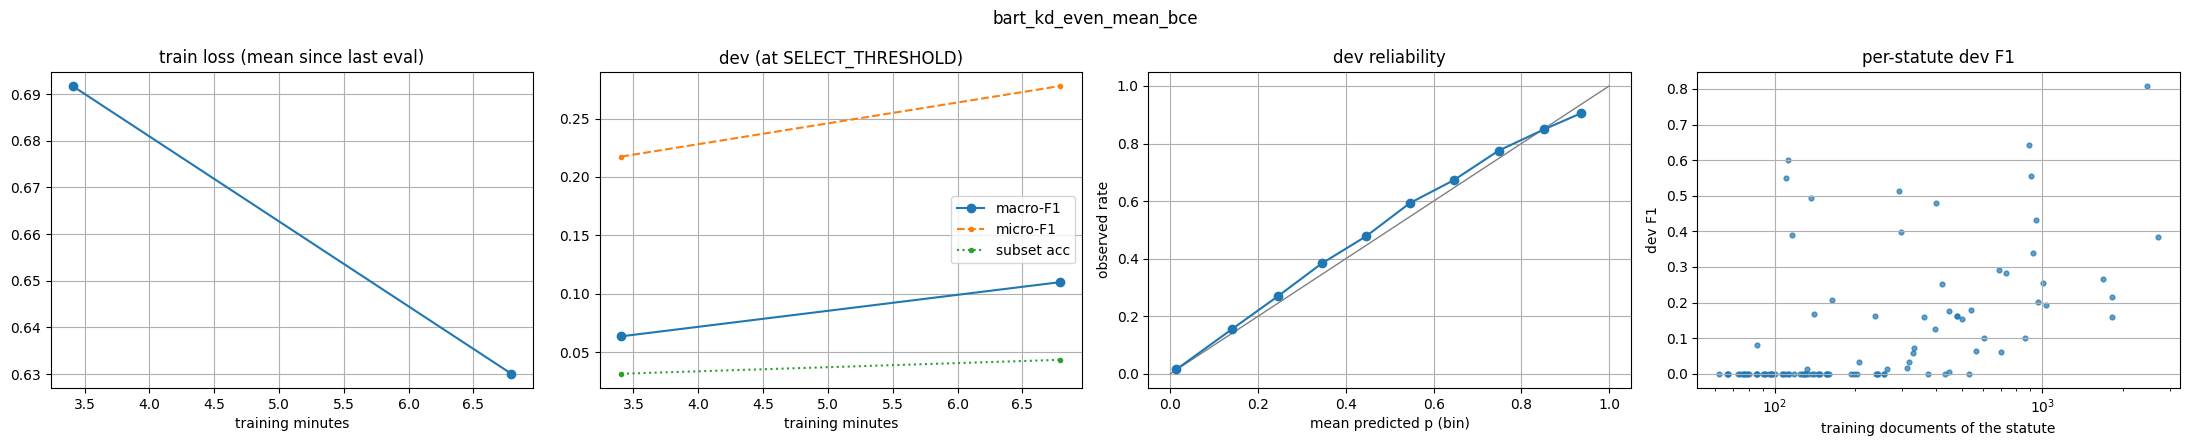

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

{
 "run": "bart_kd_even_mean_bce",
 "params_total": 46755172,
 "params_trainable": 46755172,
 "params_final": 46755172,
 "model_mb": 178.35682678222656,
 "train_minutes": 6.792010585467021,
 "peak_gpu_gb": 1.74905344,
 "peak_infer_gb": 1.268000256,
 "best": {
  "macro_F1": 0.11006579027647038,
  "epoch": 2,
  "step": 2500
 }
}
{
 "dev": {
  "macro_F1": 0.11006579027647038,
  "micro_F1": 0.27784378083405487,
  "subset_acc": 0.04361064728415676,
  "pred_per_doc": 0.9620862390727827,
  "empty_docs": 4248,
  "rejected_ids": 0,
  "n": 10181
 }
}


In [34]:
train_predict_seconds = 0.0
if SAVE_TRAIN_SCORES:
    seen = [k for k in TRAIN_KEYS if k in SEEN]
    if TRAIN_SCORES_MAX_DOCS and len(seen) > TRAIN_SCORES_MAX_DOCS:
        pick = set(np.random.default_rng(SEED).choice(len(seen), TRAIN_SCORES_MAX_DOCS, replace=False).tolist())
        seen = [k for i, k in enumerate(seen) if i in pick]
    t0 = time.time(); TL, _ = predict_logits(model, seen); train_predict_seconds = time.time() - t0
    np.savez_compressed(f"{RUN_DIR}/train_scores.npz", ids=np.array([k for _, k in seen]),
                        logits=TL.clip(-60000, 60000).astype(np.float16))
    print(f"train_scores.npz: {len(seen)} documents x {NUM_LABELS} logits ({train_predict_seconds:.0f}s)")

info = {
    "run": RUN_NAME, "arch": ARCH, "method": METHOD, "chunk_select": CHUNK_SELECT, "doc_pool": DOC_POOL, "loss": LOSS,
    "attn": ATTN, "bart_mode": BART_MODE, "p1_repo": P1_REPOS[ARCH], "layers": STUDENT_LAYERS if STUDENT else "all",
    "kept_blocks": model.kept, "n_train_docs": len(TRAIN_KEYS), "n_seen_docs": len(SEEN), "num_labels": NUM_LABELS,
    "config": {k: globals()[k] for k in ("SEED", "TRAIN_MAX_DOCS", "CHUNK_LEN", "CHUNK_STRIDE", "MAX_CHUNKS",
                                         "MAX_CHUNKS_PRED", "KEYWORDS", "POOL", "CHUNK_POS", "POS_BUCKETS", "ATT_HIDDEN",
                                         "GRU_HIDDEN", "HEAD", "HEAD_HIDDEN", "LABEL_INTERACT", "EPOCHS",
                                         "MAX_TRAIN_MINUTES", "EVAL_EVERY_MINUTES", "PATIENCE", "BATCH_DOCS",
                                         "GRAD_ACCUM", "GRAD_CKPT", "LR", "HEAD_LR", "LAYER_LR_DECAY", "WEIGHT_DECAY",
                                         "WARMUP_FRAC", "GRAD_CLIP", "DROPOUT", "SAMPLE_POWER", "POS_WEIGHT",
                                         "POS_WEIGHT_MAX", "FOCAL_GAMMA", "ASL_GAMMA_POS", "ASL_GAMMA_NEG", "ASL_CLIP",
                                         "THRESHOLD", "SELECT_THRESHOLD", "MIN_PRED", "MAX_PRED", "PRED_LABELS",
                                         "PARTIAL_TOP", "UNFREEZE_FRAC", "UNFREEZE_EMBED", "ADAPT_TARGETS", "RANK",
                                         "ALPHA", "QLORA_BLOCK", "QLORA_DOUBLE_QUANT", "LORMA_VARIANT",
                                         "ADALORA_INIT_R", "ADALORA_TARGET_R", "ADALORA_TINIT", "ADALORA_TFINAL",
                                         "ADALORA_DELTA_T", "ADALORA_BETAS", "ADALORA_ORTH", "ADAPTER_AT", "ADAPTER_DIM",
                                         "ADAPTER_TRAIN_NORMS", "PROMPT_LEN", "TEACHER_RUN", "STUDENT_LAYERS", "KD_T",
                                         "KD_ALPHA", "TRAIN_SCORES_MAX_DOCS")},
    "params_total": TOTAL_PARAMS, "params_trainable": TRAINABLE_PARAMS, "params_final": FINAL_PARAMS,
    "model_mb": FINAL_MB, "qlora": QUANT_INFO, "adalora_ranks": ADALORA_RANKS or None,
    "train_minutes": train_seconds / 60, "peak_gpu_gb": PEAK_TRAIN_GB, "peak_infer_gb": PEAK_INFER_GB,
    "best": best, "stop": stop,
    "threshold": THR if np.isscalar(THR) else {"per_label": [round(float(t), 4) for t in THR], "fallback": THR_GLOBAL},
    "dev_predict_seconds": dev_seconds, "test_predict_seconds": test_seconds,
    "train_predict_seconds": train_predict_seconds,
    "dev": dev, "dev_variants": dev_variants, "dev_mean_AP": float(np.nanmean(AP)), "dev_bce": DEV_BCE,
    "dev_by_train_freq": BY_FREQ, "dev_by_gold_count": BY_CARD, "dev_reliability": RELIABILITY,
    "dev_most_missed": miss.most_common(20), "dev_most_over_predicted": over.most_common(20),
    "dev_missed_to_predicted": [[a, b_, c] for (a, b_), c in swap.most_common(20)],
    "dev_attn_by_position": ATTN_BY_POS,
    "teacher": teacher_info and {"run": TEACHER_RUN, "arch": teacher_info["arch"], "method": teacher_info["method"],
                                 "params": teacher_info["params_final"], "model_mb": teacher_info["model_mb"],
                                 "dev_macro_F1": teacher_info["dev"]["macro_F1"],
                                 "dev_predict_seconds": teacher_info["dev_predict_seconds"]},
    "history": history,
}
json.dump(info, open(f"{RUN_DIR}/run_config.json", "w"), indent=1)
if SAVE_WEIGHTS:
    torch.save(model.state_dict(), f"{RUN_DIR}/model.pt")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 4, figsize=(22, 4.5))
tm = [h["train_minutes"] for h in history]
ax[0].plot(tm, [h["train_loss"] for h in history], marker="o"); ax[0].set_title("train loss (mean since last eval)")
ax[1].plot(tm, [h["dev_macro_F1"] for h in history], marker="o", label="macro-F1")
ax[1].plot(tm, [h["dev_micro_F1"] for h in history], marker=".", ls="--", label="micro-F1")
ax[1].plot(tm, [h["dev_subset_acc"] for h in history], marker=".", ls=":", label="subset acc")
ax[1].set_title("dev (at SELECT_THRESHOLD)"); ax[1].legend()
for a in ax[:2]: a.set_xlabel("training minutes"); a.grid(True)
rb = [r for r in RELIABILITY if r["n"]]
ax[2].plot([0, 1], [0, 1], color="grey", lw=1)
ax[2].plot([r["mean_p"] for r in rb], [r["observed"] for r in rb], marker="o")
ax[2].set_xlabel("mean predicted p (bin)"); ax[2].set_ylabel("observed rate"); ax[2].set_title("dev reliability"); ax[2].grid(True)
sel = has_dev & (TRAIN_CNT[:DEV_NL] > 0)
ax[3].scatter(TRAIN_CNT[:DEV_NL][sel], F1L[sel], s=12, alpha=0.7)
ax[3].set_xscale("log"); ax[3].set_xlabel("training documents of the statute"); ax[3].set_ylabel("dev F1")
ax[3].set_title("per-statute dev F1"); ax[3].grid(True)
fig.suptitle(RUN_NAME); plt.tight_layout(); plt.savefig(f"{RUN_DIR}/curves.png", dpi=130); plt.show()

api.create_repo(P5_REPO, private=True, exist_ok=True)
hub_push(lambda: api.upload_folder(folder_path=RUN_DIR, path_in_repo=f"runs/{RUN_NAME}", repo_id=P5_REPO,
                                   commit_message=f"{RUN_NAME} dev macro-F1 {dev['macro_F1']:.4f}"), f"runs/{RUN_NAME}")
try:
    from google.colab import files
    files.download(ZIP)
except Exception:
    pass
print(json.dumps({k: info[k] for k in ("run", "params_total", "params_trainable", "params_final", "model_mb",
                                       "train_minutes", "peak_gpu_gb", "peak_infer_gb", "best")}, indent=1))
print(json.dumps({"dev": dev}, indent=1))

## All Phase-5 runs so far (from `cs781-p5`, every account)
A table of the saved runs and a mechanical count against the §11.2 requirements (which Phase-1 models and which
§11.2.1 techniques have runs; `partial` and `unfreeze` are the same list entry). Counts only — whether two runs are
"substantially different" is your judgement.

In [35]:
TECHNIQUE = {"full": "full", "partial": "partial/layer-wise", "unfreeze": "partial/layer-wise", "qlora": "qlora",
             "lorma": "lorma", "adalora": "adalora", "adapter": "adapters", "prompt": "prompt tuning", "kd": "kd"}
runs = sorted({f.split("/")[1] for f in api.list_repo_files(P5_REPO) if f.startswith("runs/") and f.endswith("/run_config.json")})
rows = []
for r in runs:
    try:
        rows.append(json.load(open(hf_hub_download(P5_REPO, f"runs/{r}/run_config.json", token=HF_TOKEN, force_download=True))))
    except Exception as e:
        print(f"  !! {r}: {e!r}")
print(f"{'run':44s} {'arch':11s} {'method':8s} {'select':10s} {'pool':10s} {'loss':5s} {'params':>7s} {'trainable':>10s} "
      f"{'MB':>6s} {'macro-F1':>8s} {'micro-F1':>8s} {'subset':>7s} {'train min':>9s} {'dev inf s':>9s}")
for x in rows:
    dv = x["dev"]
    print(f"{x['run'][:44]:44s} {x['arch']:11s} {x['method']:8s} {x['chunk_select']:10s} {x['doc_pool']:10s} {x['loss']:5s} "
          f"{x['params_final']/1e6:6.1f}M {x['params_trainable']/1e6:9.3f}M {x['model_mb']:6.0f} {dv['macro_F1']:8.4f} "
          f"{dv['micro_F1']:8.4f} {dv['subset_acc']:7.4f} {x['train_minutes']:9.1f} {x['dev_predict_seconds']:9.1f}")
archs = {x["arch"] for x in rows}; techs = {TECHNIQUE[x["method"]] for x in rows}
print(f"\nPhase-1 models with runs: {sorted(archs)}  (missing: {sorted({'llama', 'bart', 'prefixlm', 'mistral_swa'} - archs)})")
print(f"§11.2.1 techniques with runs: {sorted(techs)}  (non-KD: {len(techs - {'kd'})})  "
      f"LoRMA: {'lorma' in techs}  KD: {'kd' in techs}")

run_config.json:   0%|          | 0.00/8.33k [00:00<?, ?B/s]

run_config.json:   0%|          | 0.00/8.66k [00:00<?, ?B/s]

run                                          arch        method   select     pool       loss   params  trainable     MB macro-F1 micro-F1  subset train min dev inf s
bart_kd_even_mean_bce                        bart        kd       even       mean       bce     46.8M    46.755M    178   0.1101   0.2778  0.0436       6.8      67.4
bart_lorma_even_mean_bce                     bart        lorma    even       mean       bce     68.0M     0.224M    259   0.1591   0.3201  0.0553      43.3     130.3

Phase-1 models with runs: ['bart']  (missing: ['llama', 'mistral_swa', 'prefixlm'])
§11.2.1 techniques with runs: ['kd', 'lorma']  (non-KD: 1)  LoRMA: True  KD: True
